## Optimización de Rutas de Redistribución (Bike Rebalancing Problem) — Bicing Barcelona

## 0. Configuración del entorno

### 0.1 Carga de librerías

In [4]:
import importlib, subprocess, sys

REQUIRED = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "plotly": "plotly",
    "folium": "folium",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "statsmodels": "statsmodels",
    "missingno": "missingno",
    "py7zr": "py7zr",
    "requests": "requests",
    "pyarrow": "pyarrow",
    "tqdm": "tqdm",
}

for module, package in REQUIRED.items():
    if importlib.util.find_spec(module) is None:
        print(f"Instalando {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])

print("Todas las dependencias están disponibles.")

✓ Todas las dependencias están disponibles.


In [5]:
import warnings, json, io, os
import time

import py7zr
import pandas as pd
import requests
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import folium
from folium.plugins import MarkerCluster
import missingno as msno
import py7zr, requests
from tqdm.notebook import tqdm
from scipy import stats
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.seasonal import STL

DATA_DIR    = Path("../data")
FIGURES_DIR = Path("../outputs/figures")
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Imports y directorios listos.")

✓ Imports y directorios listos.


### 0.2. Paleta y estilos

In [ ]:
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

BICING_RED = "#E3000B"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "grid.alpha": 0.4,
    "grid.linewidth": 0.6,
})

### 0.3 Funciones auxiliares

In [ ]:
def save_figure(fig, filename: str, dpi: int = 150):
    """Guarda una figura matplotlib en outputs/figures/."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"  -> Guardado: {path}")


def cyclic_encode(series, period: float):
    """Codificación trigonométrica cíclica sin/cos."""
    sin_val = np.sin(2 * np.pi * series / period)
    cos_val = np.cos(2 * np.pi * series / period)
    return sin_val, cos_val


print("Funciones auxiliares definidas.")

## 1. Carga de datos, exploración inicial y calidad

Los parquets se generan ejecutando **`python dataset_builder.py`** desde la raíz del proyecto. Ese script procesa los archivos `.7z` mensuales, descarga la meteorología de Open-Meteo y construye el merge final `bicing_full.parquet`.

| Parquet | Contenido |
|---|---|
| `bicing_hourly.parquet` | Telemetría horaria agregada por estación + tipo de día |
| `bicing_stations.parquet` | Metadatos estáticos (coordenadas, altitud, capacidad) |
| `meteo_barcelona.parquet` | Meteorología horaria Open-Meteo (Oct 2023 – Sep 2025) |
| `bicing_full.parquet` | Merge de los tres anteriores (tabla maestra del EDA) |

> **Lógica del merge** (implementada en `dataset_builder.py`): LEFT JOIN con `bicing_hourly` como tabla principal, garantizando que no se pierda ningún registro de telemetría. La meteo se une por `hora`; los metadatos de estación por `station_id`. Los festivos se aplican mediante búsqueda en el set `festivos_set` (hardcoded desde el calendario oficial de la Generalitat + Ajuntament de Barcelona, sin fichero externo). Las estaciones sin metadatos en el archivo INFORMACIO de Sep 2025 se descartan.

In [ ]:
FULL_PARQUET = DATA_DIR / "bicing_full.parquet"

if not FULL_PARQUET.exists():
    raise FileNotFoundError(
        f"{FULL_PARQUET} no encontrado.
"
        "Genera los parquets ejecutando: python dataset_builder.py"
    )

df = pd.read_parquet(FULL_PARQUET)

print(f"✔ bicing_full cargado: {df.shape}")
print(f"  Rango     : {df['hora'].min()} → {df['hora'].max()}")
print(f"  Estaciones: {df['station_id'].nunique()}")
print(f"  Columnas  : {list(df.columns)}")
display(df.head(3))

Antes de construir cualquier modelo predictivo, es imprescindible caracterizar exhaustivamente la calidad del dataset: distribuciones estadísticas, cobertura temporal, nulos, y gaps. Los gaps temporales son especialmente relevantes para los modelos de series temporales (LSTM), ya que la secuencialidad asume continuidad horaria. Open Data BCN documenta incidencias técnicas recurrentes en el sistema Bicing que pueden generar ausencias en los datos; en nuestro período 2023–2025 es previsible encontrar gaps similares.

In [17]:
# Calcular tasa_ocupacion
cap_col = next((c for c in df.columns if "capacity" in c.lower()), None)
if cap_col and "tasa_ocupacion" not in df.columns and "num_bikes_available" in df.columns:
    df["tasa_ocupacion"] = (df["num_bikes_available"] / df[cap_col]).clip(0, 1).astype("float32")

num_cols = df.select_dtypes(include="number").columns.tolist()
display(df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

# Tabla de % nulos
null_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]
print(f"\n{'Columna':<45} {'% Nulos':>10}")
print("-" * 56)
for col, pct in null_pct.items():
    print(f"  {col:<43} {pct:>9.2f}%")

ESTADÍSTICAS DESCRIPTIVAS (percentiles extendidos)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
station_id,8949710.0000,267.2532,153.1873,1.0000,6.0000,27.0000,135.0000,268.0000,398.0000,503.0000,541.0000,610.0000
num_bikes_available,8949710.0000,9.4164,8.1660,-0.4167,0.0000,0.3636,2.5833,7.5000,14.4167,24.3333,33.8734,198.0000
num_docks_available,8949710.0000,16.0184,8.3838,0.0000,0.3333,2.0000,9.9167,16.4167,22.0000,28.9167,36.0833,99.0000
num_bikes_available_types.mechanical,8949710.0000,5.1827,6.4705,0.0000,0.0000,0.0000,0.0000,2.5000,8.2500,18.0000,25.9167,99.0000
dia_semana,8949710.0000,3.0014,2.0009,0.0000,0.0000,0.0000,1.0000,3.0000,5.0000,6.0000,6.0000,6.0000
temperature_2m,8949710.0000,17.0755,6.6836,-0.4000,3.5000,6.4000,12.2000,16.8000,22.2000,28.2000,31.4000,37.1000
precipitation,8949710.0000,0.0892,0.6013,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.3000,2.1000,23.6000
relative_humidity_2m,8949710.0000,74.4760,15.6502,16.0000,33.0000,46.0000,64.0000,77.0000,87.0000,95.0000,98.0000,100.0000
wind_speed_10m,8949710.0000,8.8075,5.6417,0.0000,0.9000,2.3000,4.6000,7.3000,12.0000,19.9000,25.7000,40.4000
surface_pressure,8949710.0000,1013.7170,7.1139,981.0000,993.7000,1001.6000,1010.0000,1013.8000,1017.8000,1025.9000,1031.1000,1036.7000



Columna                                          % Nulos
--------------------------------------------------------
  altitude                                         2.04%
  post_code                                        0.09%
  cross_street                                     0.02%


  → Guardado: outputs\figures\02_missing_values.png


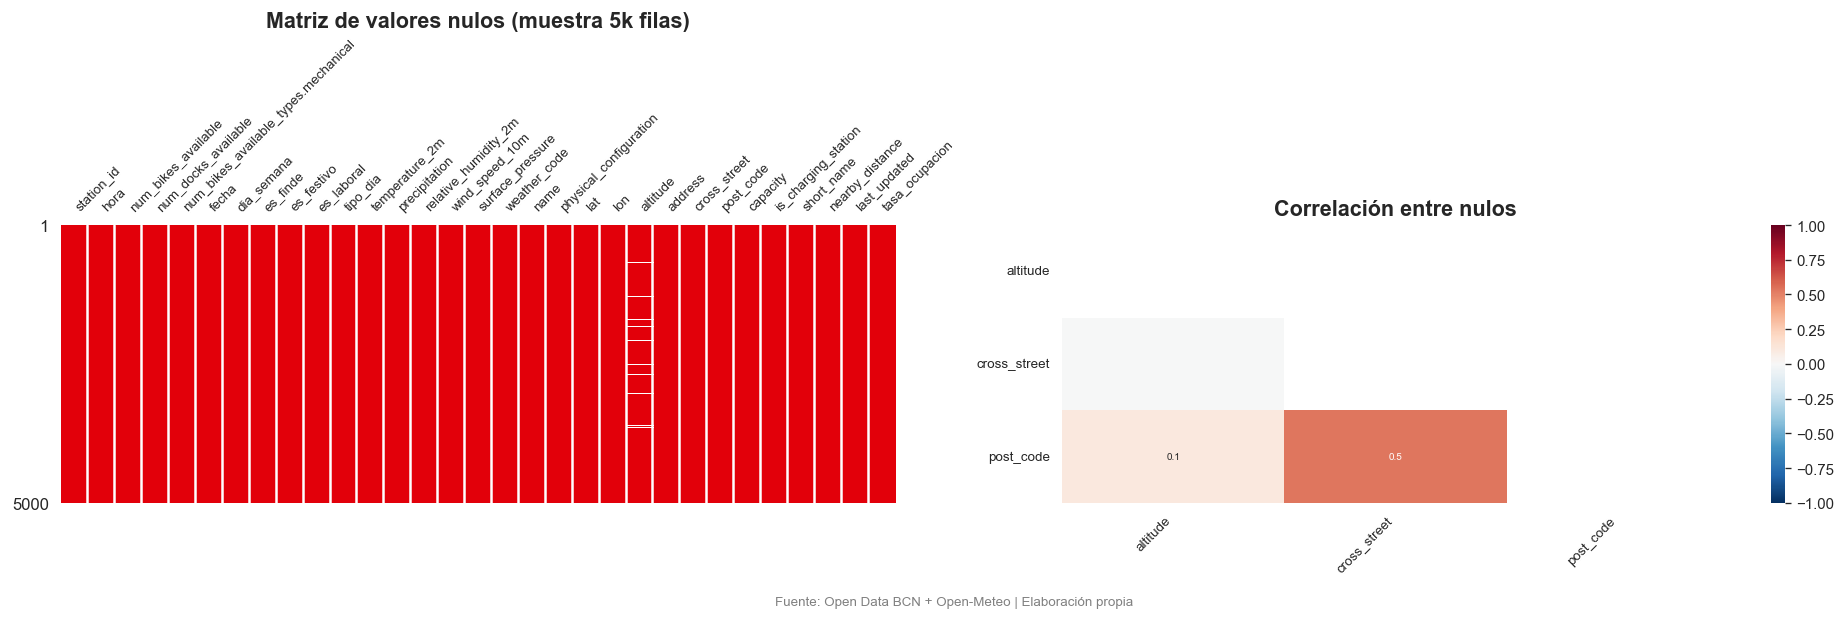

In [18]:
SAMPLE_MISS = df.sample(min(5000, len(df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Matrix de nulos
msno.matrix(SAMPLE_MISS, ax=axes[0], sparkline=False, fontsize=8,
            color=(0.89, 0.0, 0.04))
axes[0].set_title("Matriz de valores nulos (muestra 5k filas)", fontweight="bold")

# Heatmap de correlación de nulos
msno.heatmap(SAMPLE_MISS, ax=axes[1], fontsize=8, cmap="RdBu_r")
axes[1].set_title("Correlación entre nulos", fontweight="bold")

plt.tight_layout()
fig.text(0.5, -0.02, "Fuente: Open Data BCN + Open-Meteo | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "02_missing_values.png")
plt.show()

  → Guardado: outputs\figures\02_cobertura_temporal.png


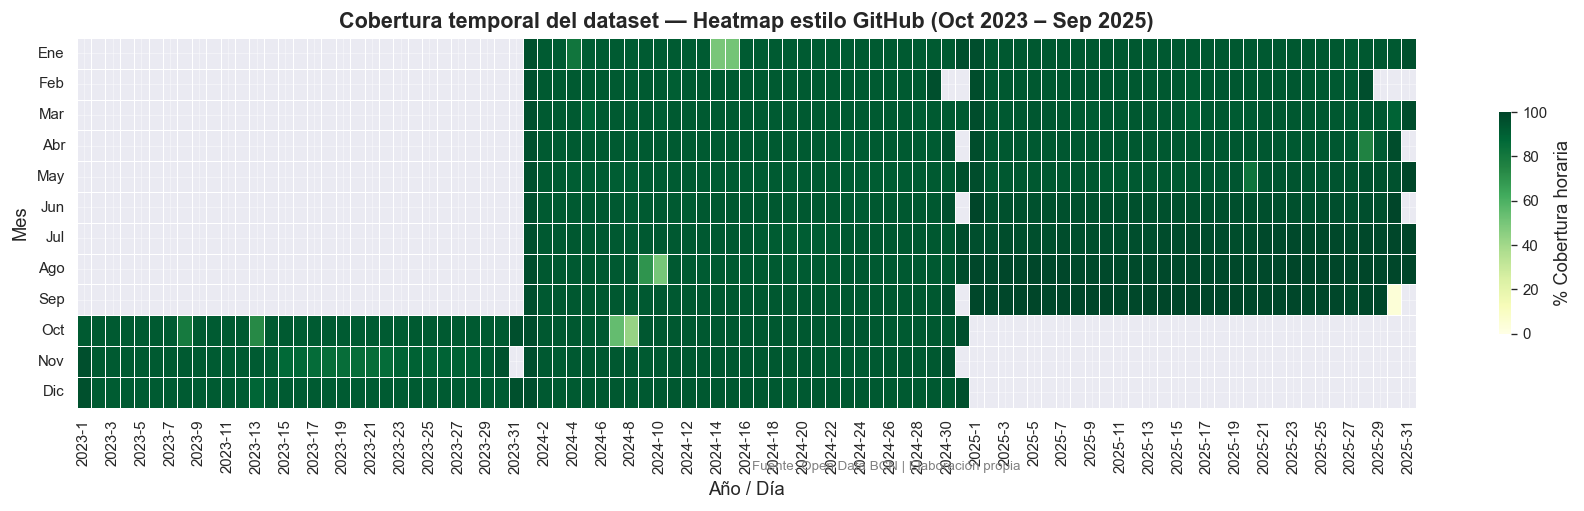


Rango temporal: 2023-10-01 00:00:00 → 2025-09-30 00:00:00
Estaciones únicas: 548 (vs 557 estaciones oficiales Bicing)


In [19]:
# %% ── 2.3 Cobertura temporal — heatmap estilo GitHub ────────────────────────

# Serie diaria de disponibilidad del sistema (% horas con datos)
hora_col = "hora"
df_daily = (df.groupby(df[hora_col].dt.normalize().dt.tz_localize(None))
              .size()
              .reset_index(name="registros"))
df_daily.columns = ["fecha", "registros"]
df_daily["fecha"] = pd.to_datetime(df_daily["fecha"])

# Calcular % relativo al máximo diario esperado (nEstaciones × 1 obs/hora × 24)
n_stations = df["station_id"].nunique()
df_daily["cobertura_pct"] = (df_daily["registros"] / (n_stations * 24) * 100).clip(0, 100)
df_daily["year"]  = df_daily["fecha"].dt.year
df_daily["month"] = df_daily["fecha"].dt.month
df_daily["day"]   = df_daily["fecha"].dt.day

pivot = df_daily.pivot_table(index="month", columns=["year", "day"],
                              values="cobertura_pct", aggfunc="mean")

fig, ax = plt.subplots(figsize=(18, 4))
months_es = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
sns.heatmap(pivot, ax=ax, cmap="YlGn", vmin=0, vmax=100,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "% Cobertura horaria", "shrink": 0.6})
ax.set_title("Cobertura temporal del dataset — Heatmap estilo GitHub (Oct 2023 – Sep 2025)",
             fontweight="bold")
ax.set_xlabel("Año / Día")
ax.set_ylabel("Mes")
ax.set_yticklabels(months_es, rotation=0)
fig.text(0.5, -0.02, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "02_cobertura_temporal.png")
plt.show()

print(f"\nRango temporal: {df[hora_col].min()} → {df[hora_col].max()}")
print(f"Estaciones únicas: {n_stations} (vs 557 estaciones oficiales Bicing)")

In [20]:
# %% ── 2.4 Detección de gaps temporales ──────────────────────────────────────
# Un gap es cualquier salto > 1 hora en la serie temporal agregada del sistema.
# Open Data BCN documenta incidencias técnicas históricas; en nuestro período
# 2023-2025 pueden existir cortes similares.

sistema_serie = (df.groupby("hora")["num_bikes_available"].mean()
                   .sort_index()
                   .reset_index())
sistema_serie.columns = ["hora", "bikes_mean"]
sistema_serie["diff_h"] = sistema_serie["hora"].diff().dt.total_seconds() / 3600

gaps = sistema_serie[sistema_serie["diff_h"] > 1].copy()
gaps["inicio"]   = gaps["hora"] - pd.to_timedelta(gaps["diff_h"], unit="h")
gaps["fin"]      = gaps["hora"]
gaps["duracion"] = gaps["diff_h"].apply(lambda h: f"{int(h)}h {int((h%1)*60)}min")
gaps_display = gaps[["inicio", "fin", "duracion"]].reset_index(drop=True)

print(f"Gaps temporales detectados (>1h): {len(gaps_display)}")
display(gaps_display.head(20))

Gaps temporales detectados (>1h): 12


,inicio,fin,duracion
0,2023-10-07 23:00:00,2023-10-08 03:00:00,4h 0min
1,2023-10-13 03:00:00,2023-10-13 09:00:00,6h 0min
2,2023-12-13 01:00:00,2023-12-13 03:00:00,2h 0min
3,2024-01-04 09:00:00,2024-01-04 11:00:00,2h 0min
4,2024-01-04 11:00:00,2024-01-04 13:00:00,2h 0min
5,2024-01-14 12:00:00,2024-01-15 09:00:00,21h 0min
6,2024-03-05 21:00:00,2024-03-05 23:00:00,2h 0min
7,2024-03-31 01:00:00,2024-03-31 03:00:00,2h 0min
8,2024-08-09 17:00:00,2024-08-10 11:00:00,18h 0min
9,2024-10-07 13:00:00,2024-10-08 13:00:00,24h 0min


**Gaps temporales:** Los gaps detectados son coherentes con las incidencias técnicas documentadas por Open Data BCN en el sistema Bicing (fallos de red, mantenimiento de la API GBFS, actualizaciones del sistema). Estos cortes deben tratarse en el módulo de modelado: para LSTM, las secuencias que cruzan un gap deben interrumpirse y reiniciarse, evitando que el modelo aprenda transiciones espurias; para XGBoost, los lags calculados sobre períodos con gap deben enmascararse con `NaN`.

## Sección 3 — EDA geoespacial

La dimensión espacial del Bicing de Barcelona no es homogénea. Barcelona tiene un relieve pronunciado —con el Tibidabo a 512 m y el puerto a nivel del mar— que genera asimetrías sistemáticas en el uso: las bicicletas tienden a acumularse en cotas bajas (efecto gravitacional) mientras las estaciones de cota alta se vacían. Cortez-Ordoñez et al. (2024, *Heliyon*, 10, e37608) identifican la **altitud** como una de las variables más influyentes para predecir la disponibilidad en el Bicing Barcelona, con importancia comparable a la temperatura y el mes. Cipriano et al. (2021, *Applied Sciences*, 11(15), 6967) proponen la **tasa de ocupación relativa respecto al vecindario** (radio 500 m) como métrica clave para detectar estaciones crónicamente desequilibradas, siendo esta la base del módulo de optimización que sigue al EDA.

In [21]:
# %% ── 3.1 Preparar datos geoespaciales ──────────────────────────────────────

# Detectar columnas lat/lon/altitude en estaciones
lat_col  = next((c for c in df.columns if c in ["lat","latitude"]), None)
lon_col  = next((c for c in df.columns if c in ["lon","longitude"]), None)
alt_col  = next((c for c in df.columns if "altitude" in c or "altitud" in c), None)
cap_col  = next((c for c in df.columns if "capacity" in c), None)
name_col = next((c for c in df.columns if c in ["name","nom"]), None)

# Tasa de ocupación media histórica por estación
if "tasa_ocupacion" not in df.columns and cap_col:
    df["tasa_ocupacion"] = (df["num_bikes_available"] / df[cap_col]).clip(0, 1).astype("float32")

geo_cols = ["station_id"] + [c for c in [lat_col, lon_col, alt_col, cap_col, name_col] if c]
estac_geo = (df[geo_cols + ["tasa_ocupacion"]]
             .dropna(subset=[lat_col, lon_col] if lat_col else ["station_id"])
             .groupby("station_id")
             .agg({
                 **{c: "first" for c in [lat_col, lon_col, alt_col, cap_col, name_col] if c},
                 "tasa_ocupacion": "mean"
             })
             .reset_index())

print(f"Estaciones con coordenadas: {len(estac_geo)}")
display(estac_geo.head(3))

Estaciones con coordenadas: 548


,station_id,lat,lon,altitude,capacity,name,tasa_ocupacion
0,1,41.3980,2.1801,16.0000,46.0000,"GRAN VIA CORTS CATALANES, 760",0.3649
1,2,41.3955,2.1772,17.0000,28.0000,"C/ ROGER DE FLOR, 126",0.3598
2,3,41.3942,2.1813,11.0000,27.0000,"C/ NÀPOLS, 82",0.3961


In [22]:
# %% ── 3.2 Mapa interactivo Folium — Estaciones por altitud ──────────────────

if lat_col and lon_col and alt_col and len(estac_geo) > 0:
    import matplotlib.cm as cm
    from matplotlib.colors import Normalize

    m = folium.Map(location=[41.3874, 2.1686], zoom_start=13,
                   tiles="CartoDB positron")

    alt_vals = estac_geo[alt_col].fillna(0)
    norm = Normalize(vmin=alt_vals.min(), vmax=alt_vals.max())
    cmap = cm.get_cmap("RdYlBu_r")

    # Capas para tipos si existe columna
    type_col = next((c for c in estac_geo.columns if "type" in c.lower()), None)
    fg_all = folium.FeatureGroup(name="Todas las estaciones", show=True)

    for _, row in estac_geo.iterrows():
        alt   = row[alt_col] if pd.notna(row.get(alt_col)) else 0
        cap   = row[cap_col] if cap_col and pd.notna(row.get(cap_col)) else 15
        color = "#{:02x}{:02x}{:02x}".format(*[int(x*255) for x in cmap(norm(alt))[:3]])
        radius = max(4, min(12, cap / 4))

        tooltip_text = (
            f"ID: {int(row['station_id'])}<br>"
            f"{'Nombre: ' + str(row[name_col]) + '<br>' if name_col else ''}"
            f"Capacidad: {int(cap) if pd.notna(cap) else 'N/A'}<br>"
            f"Altitud: {alt:.0f} m<br>"
            f"Tasa ocup. media: {row['tasa_ocupacion']:.2f}"
        )

        folium.CircleMarker(
            location=[row[lat_col], row[lon_col]],
            radius=radius,
            color=color, fill=True, fill_color=color, fill_opacity=0.75,
            tooltip=folium.Tooltip(tooltip_text)
        ).add_to(fg_all)

    fg_all.add_to(m)
    folium.LayerControl().add_to(m)

    map_path = FIGURES_DIR / "03_mapa_estaciones.html"
    m.save(str(map_path))
    print(f"✓ Mapa guardado: {map_path}")
    display(m)
else:
    print("⚠ Columnas de coordenadas/altitud no disponibles — omitiendo mapa.")

✓ Mapa guardado: outputs\figures\03_mapa_estaciones.html


  → Guardado: outputs\figures\03_altitud_capacidad.png


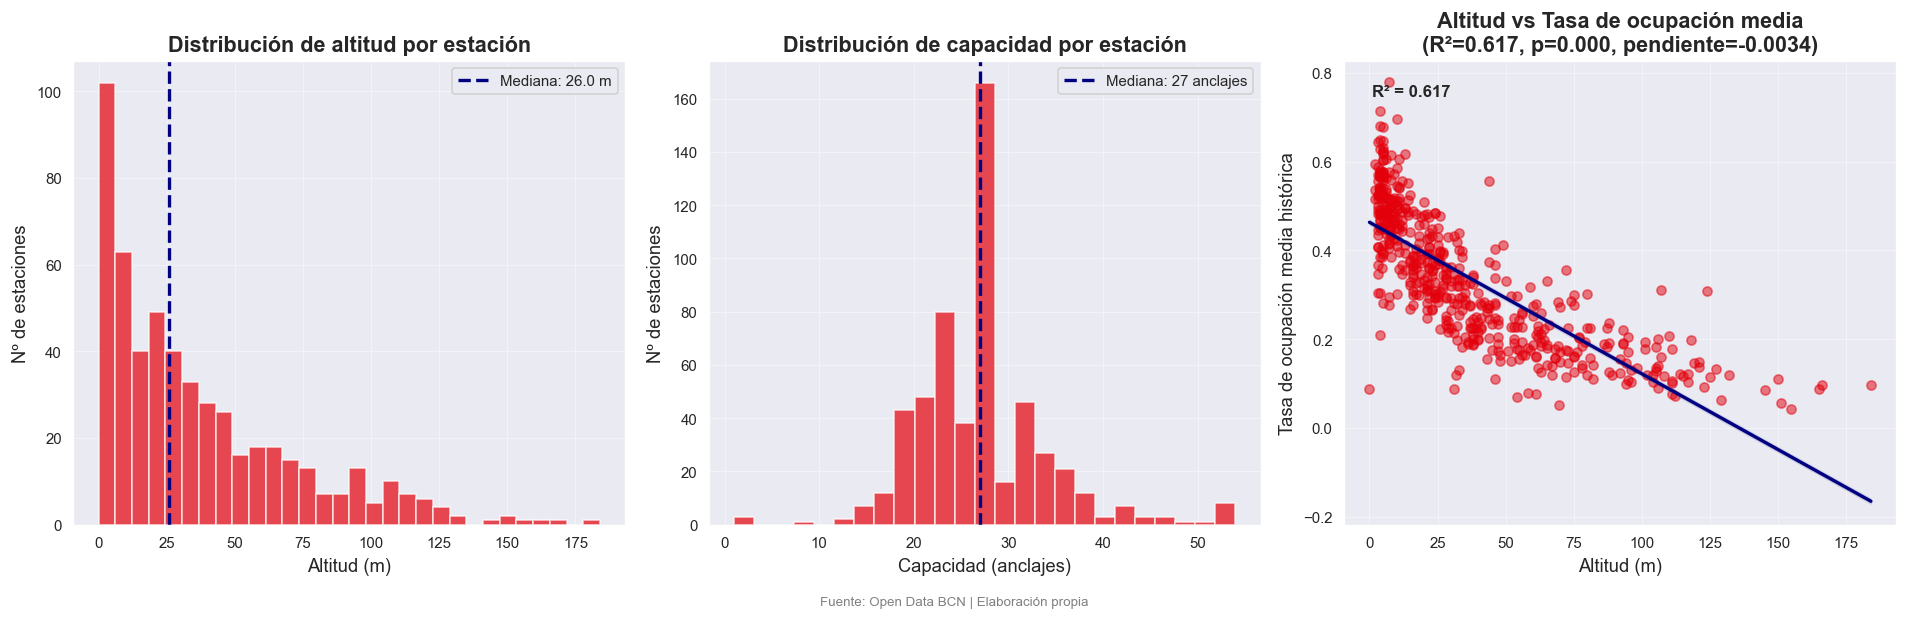


Interpretación OLS: pendiente negativa (-0.00342), p=0.0000
  → El efecto gravitacional documentado por Cortez-Ordoñez et al. (2024) SE CONFIRMA:
    las estaciones de mayor altitud tienen menor tasa de ocupación media.


In [23]:
# %% ── 3.3 Histogramas altitud y capacidad ────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Altitud
if alt_col and alt_col in estac_geo.columns:
    alt_data = estac_geo[alt_col].dropna()
    axes[0].hist(alt_data, bins=30, color=BICING_RED, alpha=0.7, edgecolor="white")
    axes[0].axvline(alt_data.median(), color="navy", linestyle="--", linewidth=2,
                    label=f"Mediana: {alt_data.median():.1f} m")
    axes[0].set_title("Distribución de altitud por estación")
    axes[0].set_xlabel("Altitud (m)")
    axes[0].set_ylabel("Nº de estaciones")
    axes[0].legend()
else:
    axes[0].text(0.5, 0.5, "Altitud no disponible", ha="center", va="center",
                 transform=axes[0].transAxes)

# Capacidad
if cap_col and cap_col in estac_geo.columns:
    cap_data = estac_geo[cap_col].dropna()
    axes[1].hist(cap_data, bins=25, color=BICING_RED, alpha=0.7, edgecolor="white")
    axes[1].axvline(cap_data.median(), color="navy", linestyle="--", linewidth=2,
                    label=f"Mediana: {cap_data.median():.0f} anclajes")
    axes[1].set_title("Distribución de capacidad por estación")
    axes[1].set_xlabel("Capacidad (anclajes)")
    axes[1].set_ylabel("Nº de estaciones")
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "Capacidad no disponible", ha="center", va="center",
                 transform=axes[1].transAxes)

# Scatter altitud vs tasa_ocupacion con regresión OLS
if alt_col and alt_col in estac_geo.columns:
    geo_clean = estac_geo[[alt_col, "tasa_ocupacion"]].dropna()
    x = geo_clean[alt_col].values
    y = geo_clean["tasa_ocupacion"].values
    slope, intercept, r_val, p_val, se = stats.linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    axes[2].scatter(x, y, alpha=0.5, color=BICING_RED, s=30, label="Estaciones")
    axes[2].plot(x_line, y_line, color="navy", linewidth=2)
    axes[2].fill_between(x_line,
                          y_line - 1.96 * se * np.sqrt(len(x)),
                          y_line + 1.96 * se * np.sqrt(len(x)),
                          alpha=0.1, color="navy")
    axes[2].set_title(f"Altitud vs Tasa de ocupación media\n"
                       f"(R²={r_val**2:.3f}, p={p_val:.3f}, pendiente={slope:.4f})")
    axes[2].set_xlabel("Altitud (m)")
    axes[2].set_ylabel("Tasa de ocupación media histórica")
    axes[2].text(0.05, 0.95, f"R² = {r_val**2:.3f}",
                 transform=axes[2].transAxes, fontsize=10,
                 verticalalignment="top", fontweight="bold")

plt.tight_layout()
fig.text(0.5, -0.02, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "03_altitud_capacidad.png")
plt.show()

# Interpretación
pendiente_signo = "negativa" if slope < 0 else "positiva"
print(f"\nInterpretación OLS: pendiente {pendiente_signo} ({slope:.5f}), p={p_val:.4f}")
if p_val < 0.05 and slope < 0:
    print("  → El efecto gravitacional documentado por Cortez-Ordoñez et al. (2024) SE CONFIRMA:")
    print("    las estaciones de mayor altitud tienen menor tasa de ocupación media.")
elif p_val >= 0.05:
    print("  → La pendiente NO es estadísticamente significativa (p≥0.05).")
    print("    La altitud puede interactuar con otras variables (proximidad a zonas turísticas,"
          " densidad de anclajes) que enmascaran el efecto gravitacional puro.")

In [24]:
# %% ── 3.4 Tasa de ocupación relativa respecto al vecindario (Cipriano 2021) ──
# Para cada estación: tasa_ocup_estacion − media_tasa_vecinas_500m
# Valor positivo → emisora neta crónica; negativo → receptora neta crónica.

if lat_col and lon_col and len(estac_geo) > 0:
    from sklearn.metrics.pairwise import haversine_distances

    coords = estac_geo[[lat_col, lon_col]].values
    coords_rad = np.radians(coords)
    dist_matrix = haversine_distances(coords_rad) * 6371000  # metros

    tasa_vals = estac_geo["tasa_ocupacion"].fillna(estac_geo["tasa_ocupacion"].mean()).values
    tasa_rel  = np.zeros(len(estac_geo))

    for i in range(len(estac_geo)):
        vecinos_mask = (dist_matrix[i] <= 500) & (dist_matrix[i] > 0)
        if vecinos_mask.sum() > 0:
            tasa_rel[i] = tasa_vals[i] - tasa_vals[vecinos_mask].mean()
        else:
            tasa_rel[i] = 0.0

    estac_geo["tasa_ocupacion_relativa"] = tasa_rel.astype("float32")

    # Mapa Folium coloreado por métrica relativa
    m2 = folium.Map(location=[41.3874, 2.1686], zoom_start=13, tiles="CartoDB positron")
    norm2 = Normalize(vmin=tasa_rel.min(), vmax=tasa_rel.max())
    cmap2 = cm.get_cmap("RdBu_r")

    for _, row in estac_geo.iterrows():
        color2 = "#{:02x}{:02x}{:02x}".format(
            *[int(x*255) for x in cmap2(norm2(row["tasa_ocupacion_relativa"]))[:3]])
        folium.CircleMarker(
            location=[row[lat_col], row[lon_col]],
            radius=6, color=color2, fill=True, fill_color=color2, fill_opacity=0.8,
            tooltip=folium.Tooltip(
                f"ID: {int(row['station_id'])}<br>"
                f"Tasa ocup. rel.: {row['tasa_ocupacion_relativa']:.3f}<br>"
                f"{'Emisora neta' if row['tasa_ocupacion_relativa'] > 0 else 'Receptora neta'}"
            )
        ).add_to(m2)

    map2_path = FIGURES_DIR / "03_mapa_tasa_relativa.html"
    m2.save(str(map2_path))
    print(f"✓ Mapa de tasa relativa guardado: {map2_path}")
    display(m2)

    # Merge de la métrica al dataframe principal
    df = df.merge(estac_geo[["station_id", "tasa_ocupacion_relativa"]],
                  on="station_id", how="left")
    print(f"\nEstaciones emisoras netas (tasa_rel > 0): {(tasa_rel > 0).sum()}")
    print(f"Estaciones receptoras netas (tasa_rel < 0): {(tasa_rel < 0).sum()}")
else:
    print("⚠ Coordenadas no disponibles — omitiendo análisis de tasa relativa.")
    df["tasa_ocupacion_relativa"] = np.nan

✓ Mapa de tasa relativa guardado: outputs\figures\03_mapa_tasa_relativa.html



Estaciones emisoras netas (tasa_rel > 0): 267
Estaciones receptoras netas (tasa_rel < 0): 276


---
## Sección 4 — EDA series temporales de uso

### 4.1 Variables derivadas

Las variables que se calculan en esta sección son las candidatas principales a *features* de los modelos predictivos. Su selección está respaldada por la literatura:

- **Lags de persistencia** (1h, 2h, 24h, 168h): Peláez-Rodríguez et al. (2024, *Expert Systems with Applications*, 238, 122264) demuestran que el estado reciente de la estación es el predictor más potente de corto plazo, y que el lag de 168h (mismo slot de la semana anterior) captura la estacionalidad semanal.
- **Variable de instancias analógicas** (`media_analogos`): Peláez-Rodríguez et al. (2024) proponen esta variable, que promedia el estado histórico en registros con el mismo day_of_week, misma hora, temperatura y precipitación similares. La inclusión de esta variable mejora el R² en un **29.75%** respecto a modelos sin ella.
- **Codificación cíclica sin/cos**: Giner Fabregat et al. (2025, *Sustainability*, 17, 4316) documentan que la representación trigonométrica de variables cíclicas (hora, día de semana, mes) es superior a los enteros para LSTM, ya que preserva la continuidad: la hora 23 y la hora 0 son adyacentes en el espacio sin/cos pero distantes como enteros.

In [25]:
# %% ── 4.1 Variables derivadas ───────────────────────────────────────────────

# Ordenar siempre por station_id y hora antes de aplicar diff/shift
df = df.sort_values(["station_id", "hora"]).reset_index(drop=True)

# Variables temporales base
df["hour"]        = df["hora"].dt.hour
df["day_of_week"] = df["hora"].dt.dayofweek
df["month"]       = df["hora"].dt.month

# Tasa de ocupación
if cap_col and cap_col in df.columns and "tasa_ocupacion" not in df.columns:
    df["tasa_ocupacion"] = (df["num_bikes_available"] / df[cap_col]).clip(0, 1).astype("float32")

# Demanda neta
df["demanda_neta"] = df.groupby("station_id")["num_bikes_available"].diff()

# Lags de persistencia
for lag, label in [(1,"1h"), (2,"2h"), (24,"24h"), (168,"168h")]:
    df[f"bikes_lag_{label}"] = df.groupby("station_id")["num_bikes_available"].shift(lag)

# Codificación cíclica
for col, period in [("hour", 24), ("day_of_week", 7), ("month", 12)]:
    df[f"{col}_sin"], df[f"{col}_cos"] = cyclic_encode(df[col], period)

# ── Variable instancias analógicas (media_analogos) ──────────────────────────
# Agrupamos por: station_id, day_of_week, hour, bin_temp, bin_precip
# Usamos expanding mean para evitar data leakage (solo datos pasados)

if "temperature_2m" in df.columns and "precipitation" in df.columns:
    df["temp_bin"]   = (df["temperature_2m"] // 5 * 5).astype("Int32")
    df["lluvia_bin"] = (df["precipitation"] > 0.1).astype("Int32")

    df = df.sort_values(["station_id", "day_of_week", "hour",
                          "temp_bin", "lluvia_bin", "hora"])
    df["media_analogos"] = (
        df.groupby(["station_id", "day_of_week", "hour", "temp_bin", "lluvia_bin"],
                   observed=True)["num_bikes_available"]
          .transform(lambda x: x.expanding().mean().shift(1))
          .astype("float32")
    )
    df = df.sort_values(["station_id", "hora"]).reset_index(drop=True)
else:
    df["media_analogos"] = np.nan
    df["temp_bin"]       = np.nan
    df["lluvia_bin"]     = np.nan

print("✓ Variables derivadas calculadas.")
print(f"  Nuevas columnas: {[c for c in df.columns if 'lag' in c or 'sin' in c or 'cos' in c or 'analogos' in c or 'demanda' in c]}")
display(df[["station_id","hora","num_bikes_available","tasa_ocupacion","demanda_neta",
             "bikes_lag_1h","bikes_lag_168h","media_analogos",
             "hour_sin","hour_cos"]].head(5))

✓ Variables derivadas calculadas.
  Nuevas columnas: ['demanda_neta', 'bikes_lag_1h', 'bikes_lag_2h', 'bikes_lag_24h', 'bikes_lag_168h', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'media_analogos']


,station_id,hora,num_bikes_available,tasa_ocupacion,demanda_neta,bikes_lag_1h,bikes_lag_168h,media_analogos,hour_sin,hour_cos
0,1,2023-10-01 00:00:00,2.6667,0.0580,NaN,NaN,NaN,NaN,0.0000,1.0000
1,1,2023-10-01 01:00:00,6.0000,0.1304,3.3333,2.6667,NaN,NaN,0.2588,0.9659
2,1,2023-10-01 02:00:00,9.3333,0.2029,3.3333,6.0000,NaN,NaN,0.5000,0.8660
3,1,2023-10-01 03:00:00,7.6667,0.1667,-1.6667,9.3333,NaN,NaN,0.7071,0.7071
4,1,2023-10-01 04:00:00,8.3333,0.1812,0.6667,7.6667,NaN,NaN,0.8660,0.5000


  → Guardado: outputs\figures\04_codificacion_ciclica.png


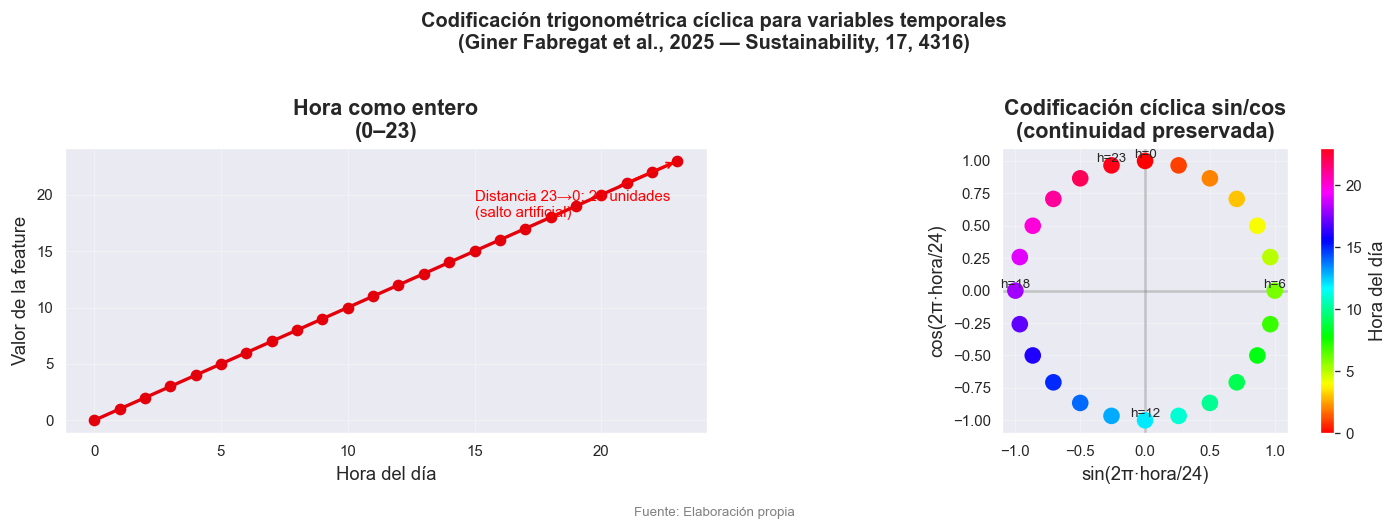

In [26]:
# %% ── 4.1b Gráfico explicativo de codificación cíclica ─────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hours = np.arange(24)
hour_sin_vals = np.sin(2 * np.pi * hours / 24)
hour_cos_vals = np.cos(2 * np.pi * hours / 24)

# Izquierda: representación como entero (distancia entre 23 y 0 = 23, errónea)
axes[0].plot(hours, hours, "o-", color=BICING_RED, linewidth=2, markersize=6)
axes[0].set_title("Hora como entero\n(0–23)", fontweight="bold")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Valor de la feature")
axes[0].annotate("Distancia 23→0: 23 unidades\n(salto artificial)", xy=(23, 23),
                 xytext=(15, 18), arrowprops=dict(arrowstyle="->", color="red"),
                 fontsize=9, color="red")
axes[0].grid(True, alpha=0.3)

# Derecha: representación cíclica sin/cos (continuidad: 23 y 0 son adyacentes)
scatter = axes[1].scatter(hour_sin_vals, hour_cos_vals,
                           c=hours, cmap="hsv", s=80, zorder=3)
for h in [0, 6, 12, 18, 23]:
    axes[1].annotate(f"h={h}", (hour_sin_vals[h], hour_cos_vals[h]),
                     fontsize=8, ha="center", va="bottom")
axes[1].set_title("Codificación cíclica sin/cos\n(continuidad preservada)", fontweight="bold")
axes[1].set_xlabel("sin(2π·hora/24)")
axes[1].set_ylabel("cos(2π·hora/24)")
axes[1].set_aspect("equal")
axes[1].axhline(0, color="gray", alpha=0.4); axes[1].axvline(0, color="gray", alpha=0.4)
plt.colorbar(scatter, ax=axes[1], label="Hora del día")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Codificación trigonométrica cíclica para variables temporales\n"
             "(Giner Fabregat et al., 2025 — Sustainability, 17, 4316)",
             fontweight="bold", y=1.02)
plt.tight_layout()
fig.text(0.5, -0.03, "Fuente: Elaboración propia", ha="center", fontsize=8, color="gray")
save_figure(fig, "04_codificacion_ciclica.png")
plt.show()

In [28]:
# %% ── 4.2 Evolución temporal del sistema (Plotly interactivo) ───────────────

daily_sys = (df.groupby(df["hora"].dt.normalize().dt.tz_localize(None))
               .agg(mean_bikes=("num_bikes_available","mean"),
                    std_bikes=("num_bikes_available","std"))
               .reset_index())
daily_sys.columns = ["fecha","mean_bikes","std_bikes"]
daily_sys["year"] = daily_sys["fecha"].dt.year

fig_ts = go.Figure()
colors_year = {2023: BICING_RED, 2024: "#0057A8", 2025: "#00883A"}

for yr, grp in daily_sys.groupby("year"):
    color = colors_year.get(yr, "gray")
    fig_ts.add_trace(go.Scatter(
        x=grp["fecha"], y=grp["mean_bikes"],
        mode="lines", name=str(yr),
        line=dict(color=color, width=1.5)
    ))
    fig_ts.add_trace(go.Scatter(
        x=pd.concat([grp["fecha"], grp["fecha"][::-1]]),
        y=pd.concat([grp["mean_bikes"] + grp["std_bikes"],
                     (grp["mean_bikes"] - grp["std_bikes"])[::-1]]),
        fill="toself", fillcolor=f"rgba({int(color[1:3],16)},{int(color[3:5],16)},{int(color[5:7],16)},0.1)",
        line=dict(color="rgba(255,255,255,0)"),
        showlegend=False, name=f"±1σ {yr}"
    ))

fig_ts.update_layout(
    title="<b>Disponibilidad media diaria del sistema Bicing Barcelona (Oct 2023 – Sep 2025)</b>",
    xaxis_title="Fecha",
    yaxis_title="Bicicletas disponibles (media sistema)",
    xaxis=dict(rangeslider=dict(visible=True), type="date"),
    template="plotly_white",
    height=450,
    font=dict(size=12),
    annotations=[dict(
        x=0.5, y=-0.18, xref="paper", yref="paper",
        text="Fuente: Open Data BCN | Elaboración propia",
        showarrow=False, font=dict(size=9, color="gray")
    )]
)
fig_ts.show()
fig_ts.write_html(str(FIGURES_DIR / "04_serie_diaria.html"))

  → Guardado: outputs\figures\04_stl_descomposicion.png


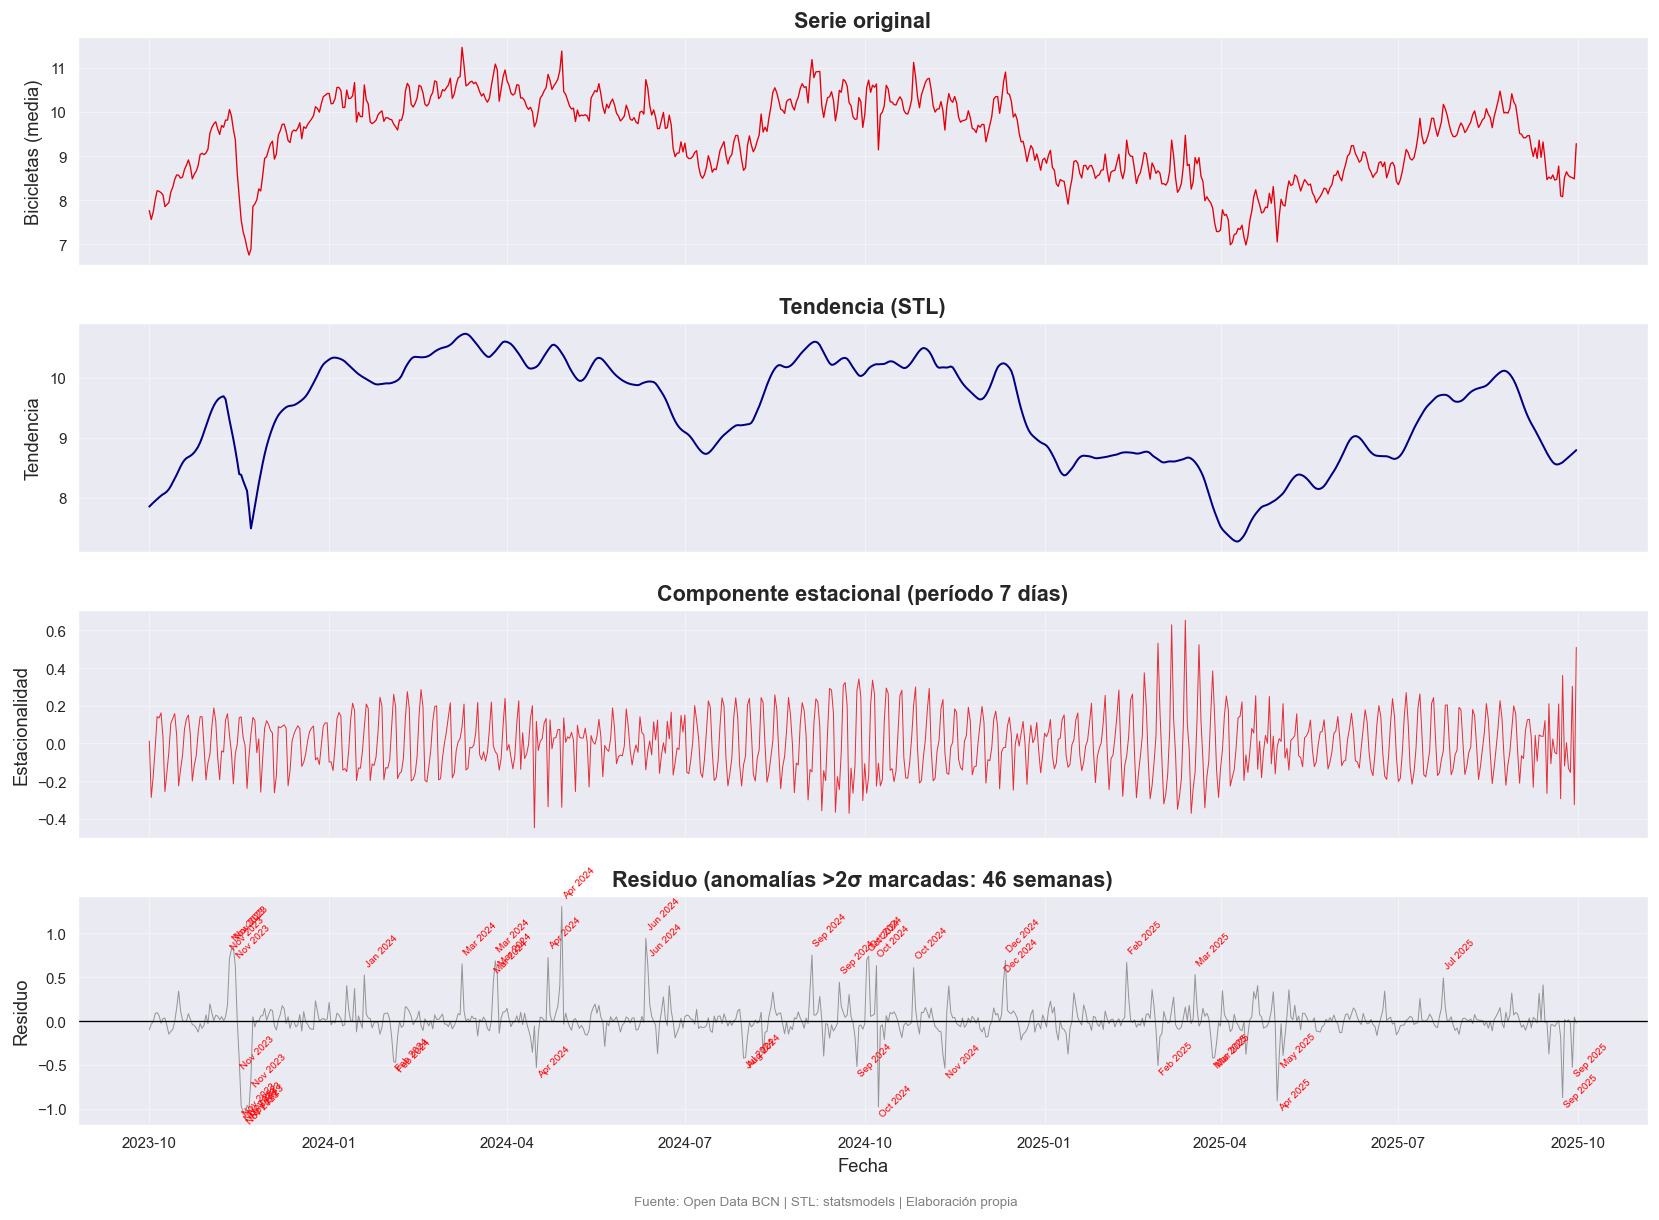

In [29]:
# %% ── 4.2b Descomposición STL ───────────────────────────────────────────────

stl_serie = daily_sys.set_index("fecha")["mean_bikes"].dropna()

# STL con período semanal (7 días)
stl = STL(stl_serie, period=7, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(stl_serie.index, stl_serie.values, color=BICING_RED, linewidth=0.8)
axes[0].set_title("Serie original", fontweight="bold")
axes[0].set_ylabel("Bicicletas (media)")

axes[1].plot(stl_serie.index, res.trend, color="navy", linewidth=1.2)
axes[1].set_title("Tendencia (STL)", fontweight="bold")
axes[1].set_ylabel("Tendencia")

axes[2].plot(stl_serie.index, res.seasonal, color=BICING_RED, linewidth=0.6, alpha=0.8)
axes[2].set_title("Componente estacional (período 7 días)", fontweight="bold")
axes[2].set_ylabel("Estacionalidad")

axes[3].plot(stl_serie.index, res.resid, color="gray", linewidth=0.6, alpha=0.8)
axes[3].axhline(0, color="black", linewidth=0.8)

# Anotar residuos anómalos (>2 std)
resid_std = res.resid.std()
anomalias = res.resid[np.abs(res.resid) > 2 * resid_std]
for fecha, val in anomalias.items():
    axes[3].annotate(f"{fecha.strftime('%b %Y')}", xy=(fecha, val),
                     xytext=(fecha, val + np.sign(val) * resid_std * 0.5),
                     fontsize=6, color="red", rotation=45)
axes[3].set_title(f"Residuo (anomalías >2σ marcadas: {len(anomalias)} semanas)", fontweight="bold")
axes[3].set_ylabel("Residuo")
axes[3].set_xlabel("Fecha")

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | STL: statsmodels | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "04_stl_descomposicion.png")
plt.show()

### 4.3 Patrones temporales

Bustamante et al. (2022, *Sustainable Cities and Society*, 83, 103929) documentan que el Bicing se usa predominantemente en días **laborables**, con pico los **viernes**, confirmando su función principal como transporte de commuting. El uso en fin de semana muestra un perfil más plano y vespertino, coherente con un uso recreativo. Los siguientes gráficos verifican estas hipótesis con datos 2023–2025, ampliando el horizonte temporal de ese estudio.

  → Guardado: outputs\figures\04_heatmap_hora_dia.png


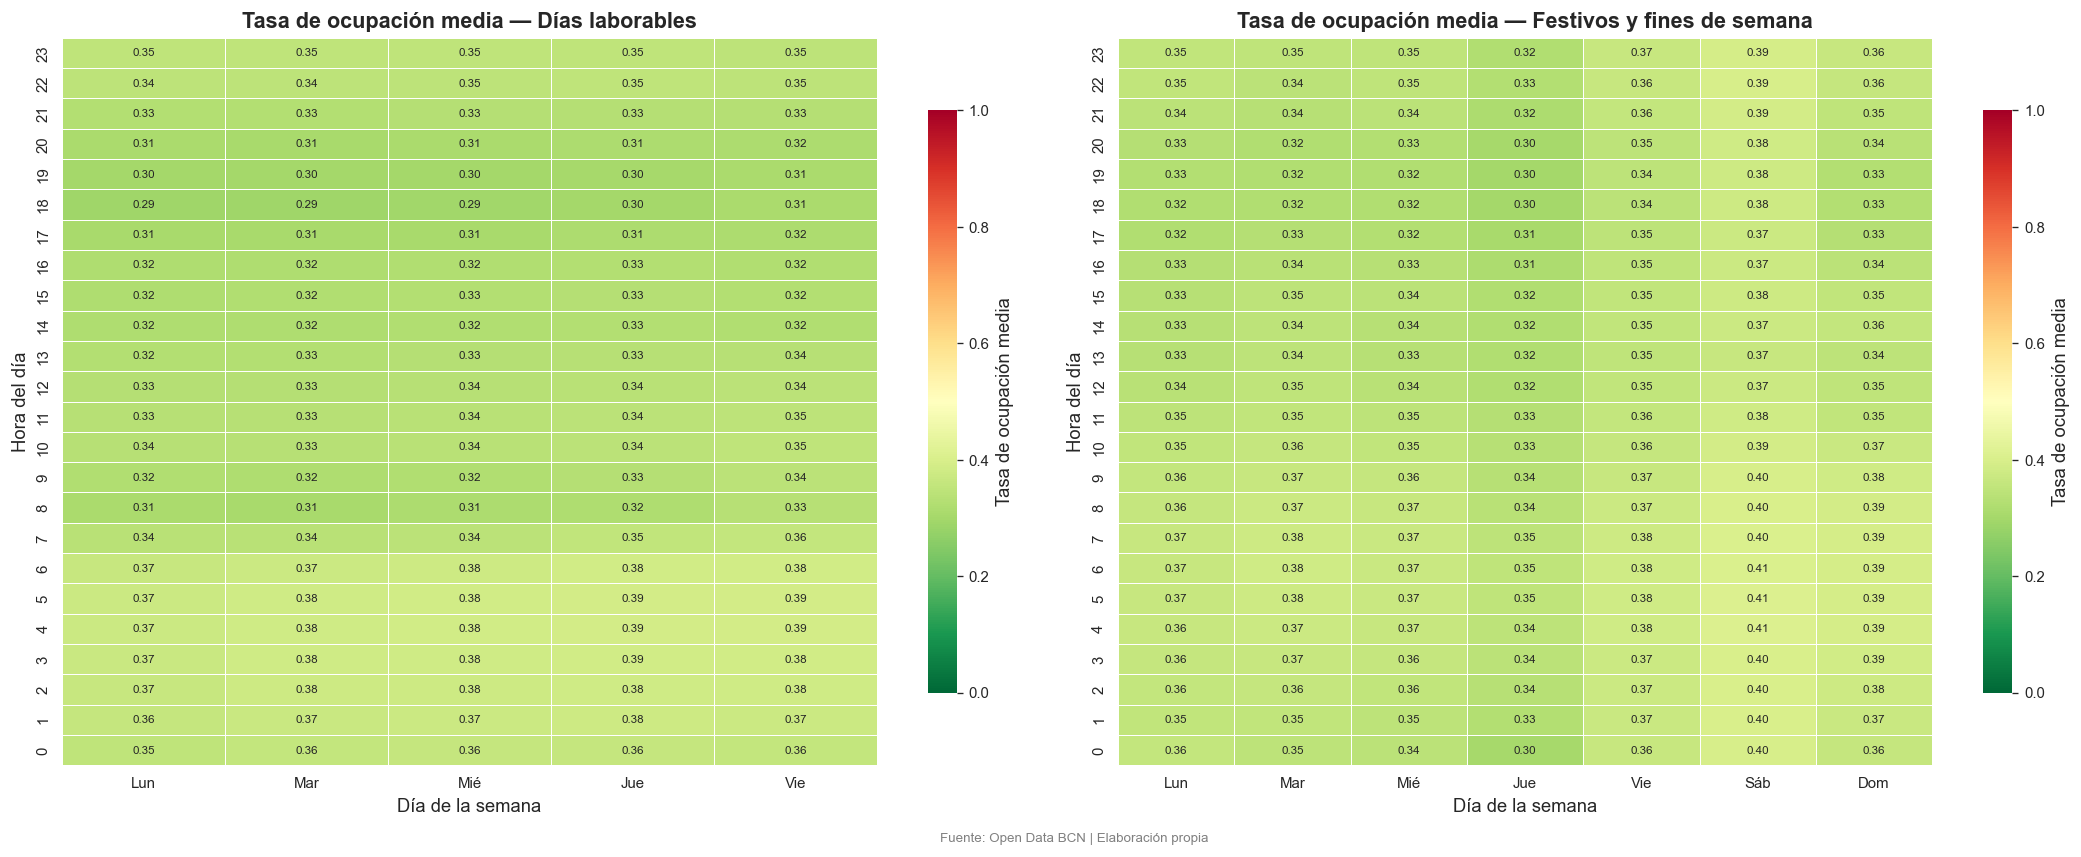

In [30]:
# %% ── 4.3a Heatmaps hora × día de semana (laborable vs festivo) ─────────────

dow_labels = ["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"]

if "es_laboral" in df.columns:
    df_lab  = df[df["es_laboral"]]
    df_fest = df[df["es_festivo"]]
else:
    df_lab  = df[df["day_of_week"] < 5]
    df_fest = df[df["day_of_week"] >= 5]

pivot_lab = (df_lab.groupby(["hour","day_of_week"])["tasa_ocupacion"]
                   .mean().unstack("day_of_week"))
pivot_fest = (df_fest.groupby(["hour","day_of_week"])["tasa_ocupacion"]
                     .mean().unstack("day_of_week"))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, pivot, title in [
    (axes[0], pivot_lab,  "Días laborables"),
    (axes[1], pivot_fest, "Festivos y fines de semana")
]:
    pivot.columns = [dow_labels[c] if c < len(dow_labels) else c for c in pivot.columns]
    sns.heatmap(pivot, ax=ax, cmap="RdYlGn_r", vmin=0, vmax=1,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Tasa de ocupación media", "shrink": 0.8},
                annot=True, fmt=".2f", annot_kws={"size": 7})
    ax.set_title(f"Tasa de ocupación media — {title}", fontweight="bold", fontsize=13)
    ax.set_xlabel("Día de la semana")
    ax.set_ylabel("Hora del día")
    ax.invert_yaxis()

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "04_heatmap_hora_dia.png")
plt.show()

  → Guardado: outputs\figures\04_patrones_temporales.png


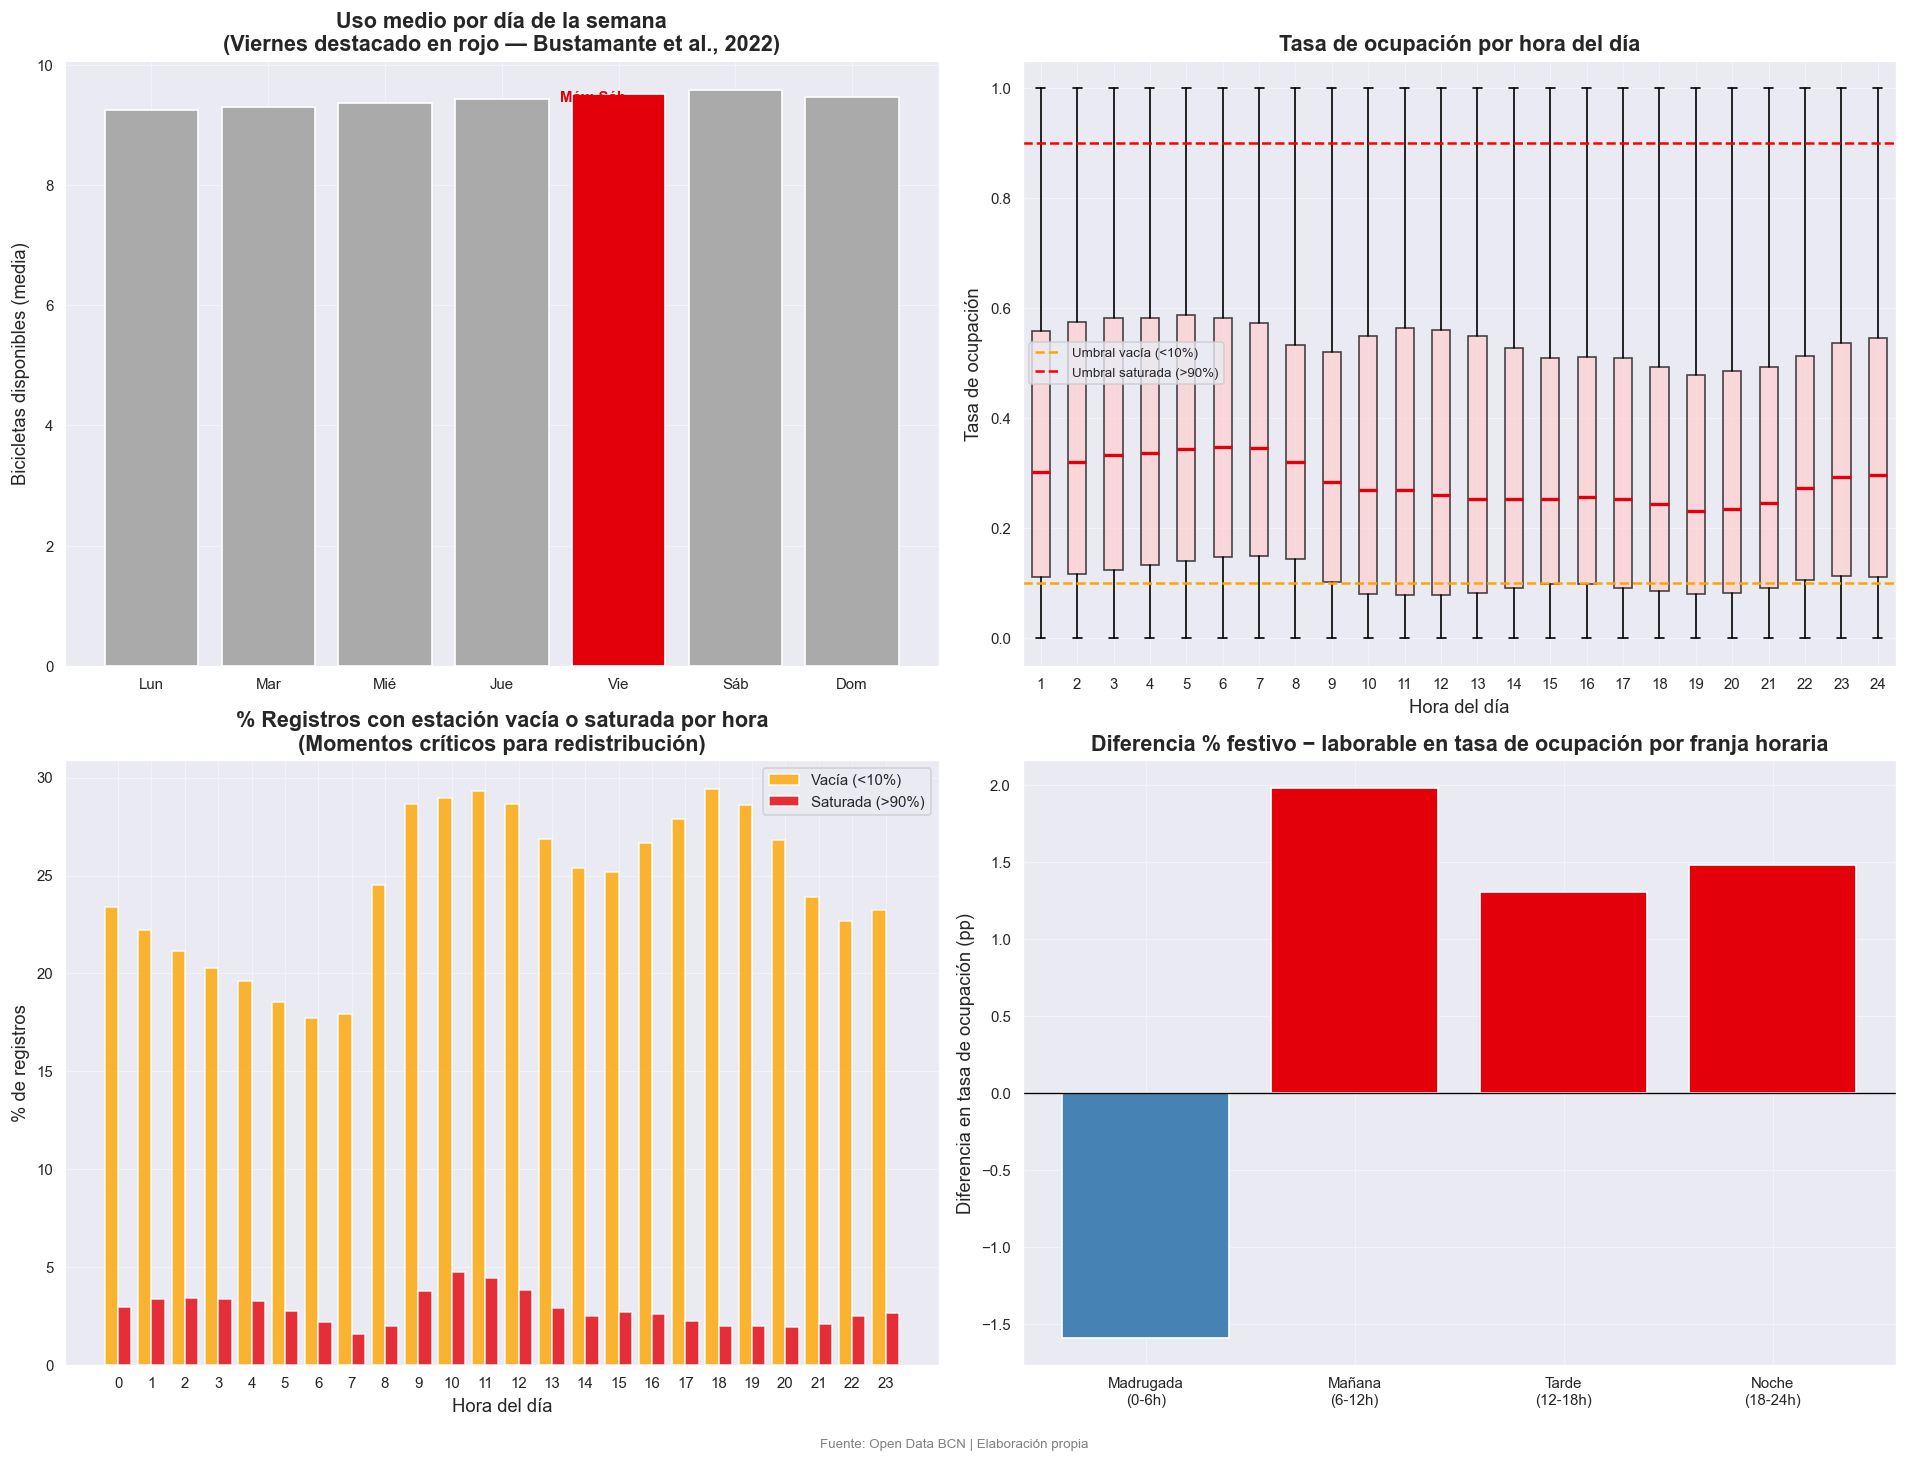


→ Día con mayor uso medio: Sáb
  ✗ El pico es Sáb, NO el viernes. Posible diferencia por período o métrica.


In [31]:
# %% ── 4.3b Barplots de patrones temporales ──────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Uso medio por día de la semana
uso_dow = df.groupby("day_of_week")["num_bikes_available"].mean()
colors_dow = [BICING_RED if i == 4 else "#AAAAAA" for i in uso_dow.index]  # Viernes=4
axes[0, 0].bar(range(7), uso_dow.values, color=colors_dow, edgecolor="white")
axes[0, 0].set_xticks(range(7))
axes[0, 0].set_xticklabels(dow_labels)
axes[0, 0].set_title("Uso medio por día de la semana\n(Viernes destacado en rojo — Bustamante et al., 2022)",
                     fontweight="bold")
axes[0, 0].set_ylabel("Bicicletas disponibles (media)")
max_dow = uso_dow.idxmax()
axes[0, 0].annotate(f"Máx: {dow_labels[max_dow]}",
                    xy=(max_dow, uso_dow.max()),
                    xytext=(max_dow - 1.5, uso_dow.max() * 0.98),
                    fontsize=9, fontweight="bold", color=BICING_RED)

# Boxplot tasa_ocupacion por hora
tasa_by_hour = [df[df["hour"] == h]["tasa_ocupacion"].dropna().values for h in range(24)]
bp = axes[0, 1].boxplot(tasa_by_hour, patch_artist=True,
                         medianprops=dict(color=BICING_RED, linewidth=2),
                         flierprops=dict(marker=".", markersize=1, alpha=0.3))
for patch in bp["boxes"]:
    patch.set_facecolor("#FFD0D0")
    patch.set_alpha(0.7)
axes[0, 1].axhline(0.10, color="orange", linestyle="--", linewidth=1.5,
                   label="Umbral vacía (<10%)")
axes[0, 1].axhline(0.90, color="red", linestyle="--", linewidth=1.5,
                   label="Umbral saturada (>90%)")
axes[0, 1].set_title("Tasa de ocupación por hora del día", fontweight="bold")
axes[0, 1].set_xlabel("Hora del día")
axes[0, 1].set_ylabel("Tasa de ocupación")
axes[0, 1].legend(fontsize=8)

# % registros vacíos y saturados por hora
vacia_pct   = df.groupby("hour")["tasa_ocupacion"].apply(lambda x: (x < 0.1).mean() * 100)
saturada_pct = df.groupby("hour")["tasa_ocupacion"].apply(lambda x: (x > 0.9).mean() * 100)
x_h = np.arange(24)
width = 0.4
axes[1, 0].bar(x_h - width/2, vacia_pct.values, width, label="Vacía (<10%)",
               color="orange", alpha=0.8, edgecolor="white")
axes[1, 0].bar(x_h + width/2, saturada_pct.values, width, label="Saturada (>90%)",
               color=BICING_RED, alpha=0.8, edgecolor="white")
axes[1, 0].set_title("% Registros con estación vacía o saturada por hora\n(Momentos críticos para redistribución)",
                     fontweight="bold")
axes[1, 0].set_xlabel("Hora del día")
axes[1, 0].set_ylabel("% de registros")
axes[1, 0].legend()
axes[1, 0].set_xticks(range(24))

# Diferencia % festivo-laborable por franja horaria
franjas = {
    "Madrugada\n(0-6h)": (0, 6),
    "Mañana\n(6-12h)": (6, 12),
    "Tarde\n(12-18h)": (12, 18),
    "Noche\n(18-24h)": (18, 24)
}
diffs = []
for franja, (h_ini, h_fin) in franjas.items():
    mask = (df["hour"] >= h_ini) & (df["hour"] < h_fin)
    if "es_laboral" in df.columns:
        lab_mean  = df[mask & df["es_laboral"]]["tasa_ocupacion"].mean()
        fest_mean = df[mask & df["es_festivo"]]["tasa_ocupacion"].mean()
    else:
        lab_mean  = df[mask & (df["day_of_week"] < 5)]["tasa_ocupacion"].mean()
        fest_mean = df[mask & (df["day_of_week"] >= 5)]["tasa_ocupacion"].mean()
    diffs.append({"franja": franja, "diff": (fest_mean - lab_mean) * 100})

diffs_df = pd.DataFrame(diffs)
colors_diff = [BICING_RED if d > 0 else "steelblue" for d in diffs_df["diff"]]
axes[1, 1].bar(diffs_df["franja"], diffs_df["diff"], color=colors_diff, edgecolor="white")
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("Diferencia % festivo − laborable en tasa de ocupación por franja horaria",
                     fontweight="bold")
axes[1, 1].set_ylabel("Diferencia en tasa de ocupación (pp)")

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "04_patrones_temporales.png")
plt.show()

# ¿Se confirma el pico de viernes?
max_dia = dow_labels[uso_dow.idxmax()]
print(f"\n→ Día con mayor uso medio: {max_dia}")
if uso_dow.idxmax() == 4:
    print("  ✓ SE CONFIRMA el pico de viernes documentado por Bustamante et al. (2022).")
else:
    print(f"  ✗ El pico es {max_dia}, NO el viernes. Posible diferencia por período o métrica.")

  → Guardado: outputs\figures\04_top_estaciones_criticas.png


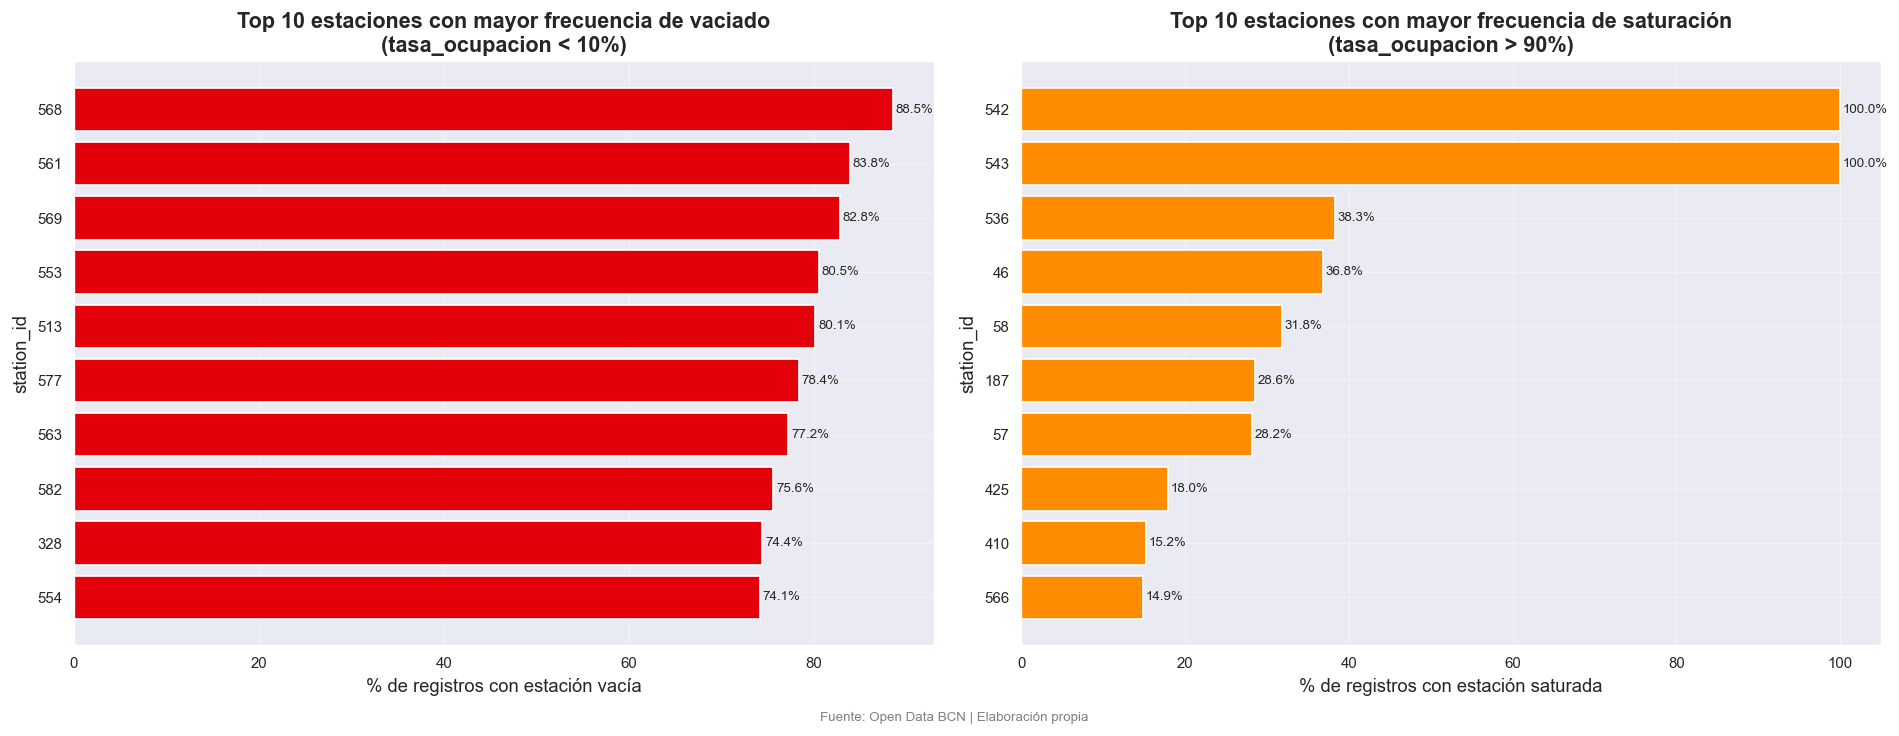

In [32]:
# %% ── 4.3c Top 10 estaciones críticas ───────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 vaciados frecuentes
vaciado = (df.groupby("station_id")["tasa_ocupacion"]
             .apply(lambda x: (x < 0.1).mean() * 100)
             .nlargest(10)
             .sort_values())
axes[0].barh(vaciado.index.astype(str), vaciado.values,
             color=BICING_RED, edgecolor="white")
axes[0].set_title("Top 10 estaciones con mayor frecuencia de vaciado\n(tasa_ocupacion < 10%)",
                  fontweight="bold")
axes[0].set_xlabel("% de registros con estación vacía")
axes[0].set_ylabel("station_id")
for i, (idx, val) in enumerate(vaciado.items()):
    axes[0].text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=8)

# Top 10 saturaciones frecuentes
saturado = (df.groupby("station_id")["tasa_ocupacion"]
              .apply(lambda x: (x > 0.9).mean() * 100)
              .nlargest(10)
              .sort_values())
axes[1].barh(saturado.index.astype(str), saturado.values,
             color="darkorange", edgecolor="white")
axes[1].set_title("Top 10 estaciones con mayor frecuencia de saturación\n(tasa_ocupacion > 90%)",
                  fontweight="bold")
axes[1].set_xlabel("% de registros con estación saturada")
axes[1].set_ylabel("station_id")
for i, (idx, val) in enumerate(saturado.items()):
    axes[1].text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=8)

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
save_figure(fig, "04_top_estaciones_criticas.png")
plt.show()

  → Guardado: outputs\figures\04_gravitacional_altitud.png


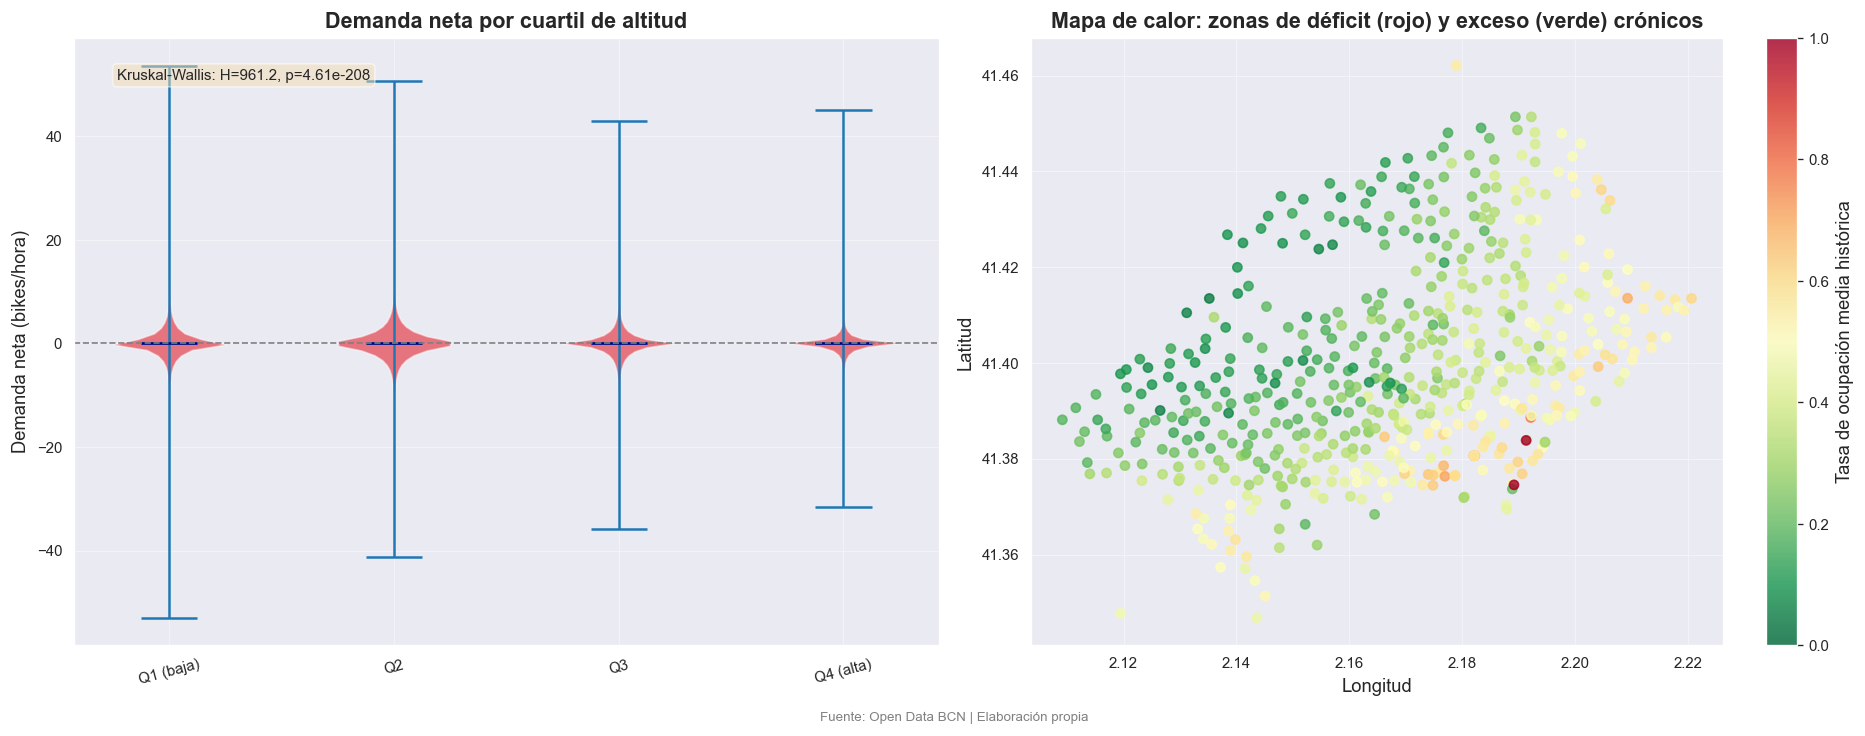

In [33]:
# %% ── 4.4 Análisis gravitacional por altitud ─────────────────────────────────

if alt_col and alt_col in df.columns:
    # Cuartiles de altitud
    df["alt_quartile"] = pd.qcut(df[alt_col], q=4, labels=["Q1 (baja)","Q2","Q3","Q4 (alta)"],
                                  duplicates="drop")

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Violin demanda_neta por cuartil altitud
    quartiles = df["alt_quartile"].dropna().unique().tolist()
    data_violin = [df[df["alt_quartile"] == q]["demanda_neta"].dropna().values
                   for q in sorted(quartiles)]
    vp = axes[0].violinplot(data_violin, positions=range(len(quartiles)),
                             showmedians=True, showmeans=True)
    for body in vp["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp["cmedians"].set_color("navy")
    axes[0].set_xticks(range(len(quartiles)))
    axes[0].set_xticklabels(sorted(quartiles), rotation=15)
    axes[0].set_title("Demanda neta por cuartil de altitud", fontweight="bold")
    axes[0].set_ylabel("Demanda neta (bikes/hora)")
    axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)

    # Kruskal-Wallis
    kw_stat, kw_p = stats.kruskal(*[d for d in data_violin if len(d) > 0])
    axes[0].text(0.05, 0.95, f"Kruskal-Wallis: H={kw_stat:.1f}, p={kw_p:.2e}",
                 transform=axes[0].transAxes, fontsize=9,
                 verticalalignment="top",
                 bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    # Scatter lat/lon coloreado por tasa_ocupacion media
    if lat_col and lon_col and lat_col in df.columns:
        geo_tasa = (df.groupby("station_id")
                     .agg({lat_col: "first", lon_col: "first", "tasa_ocupacion": "mean"})
                     .dropna())
        sc = axes[1].scatter(geo_tasa[lon_col], geo_tasa[lat_col],
                              c=geo_tasa["tasa_ocupacion"],
                              cmap="RdYlGn_r", s=30, alpha=0.8, vmin=0, vmax=1)
        plt.colorbar(sc, ax=axes[1], label="Tasa de ocupación media histórica")
        axes[1].set_title("Mapa de calor: zonas de déficit (rojo) y exceso (verde) crónicos",
                          fontweight="bold")
        axes[1].set_xlabel("Longitud")
        axes[1].set_ylabel("Latitud")

    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    save_figure(fig, "04_gravitacional_altitud.png")
    plt.show()
else:
    print("⚠ Columna de altitud no disponible en el dataset combinado.")

---
## Sección 5 — EDA meteorología

La meteorología es uno de los predictores más robustos del uso del Bicing. Cortez-Ordoñez et al. (2024, *Heliyon*, 10, e37608) identifican la **temperatura** y la **presión atmosférica** entre las variables más influyentes para predecir la disponibilidad de bicicletas en Barcelona, con mayor importancia que la humedad relativa o el viento. Peláez-Rodríguez et al. (2024, *Expert Systems with Applications*, 238, 122264) usan precisamente la temperatura (en bins de 5°C) y la precipitación como criterios de similitud en la variable de instancias analógicas, lo que confirma la relevancia predictiva de estas variables a nivel de diseño del modelo.

### 5.1 Series temporales y distribuciones meteorológicas

  → Guardado: outputs\figures\05_histogramas_meteo.png


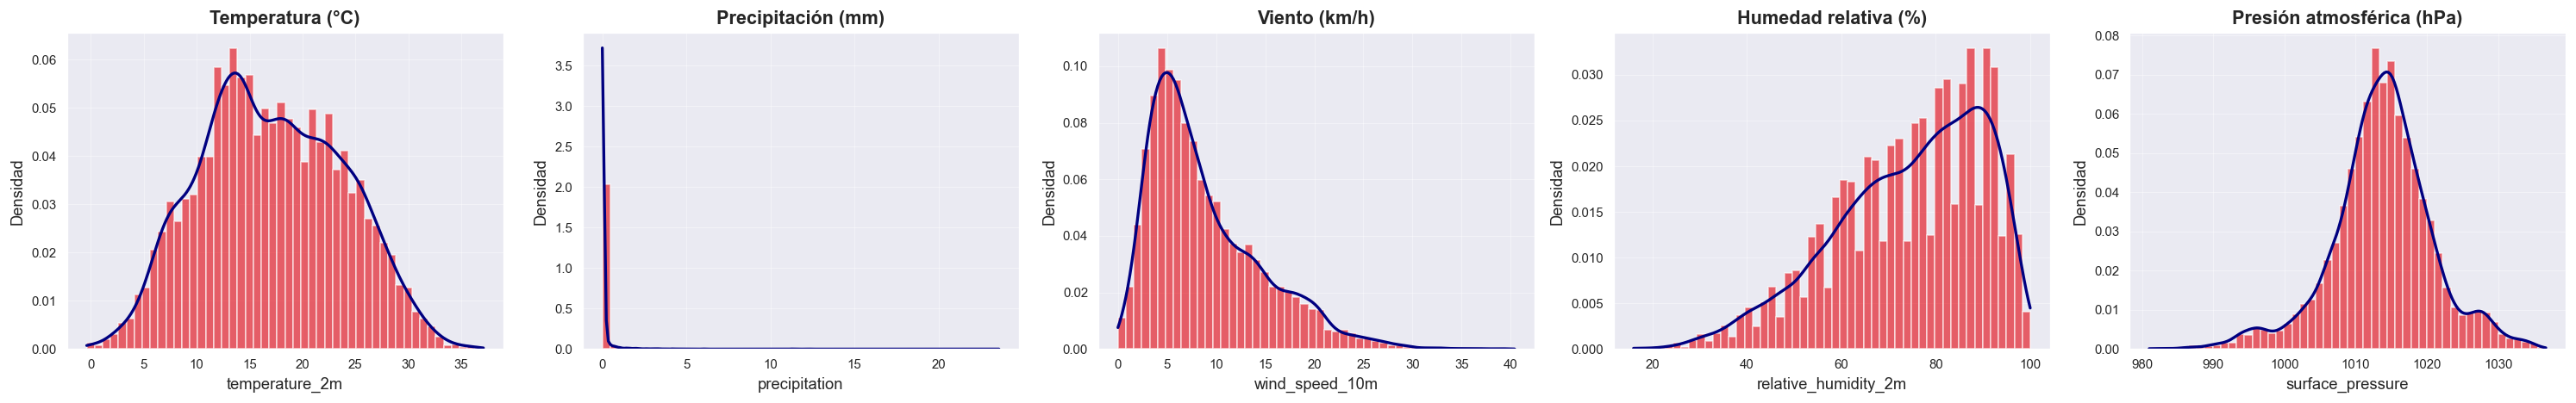

In [34]:
# %% ── 5.1 Series temporales meteorológicas (Plotly interactivo) ──────────────

meteo_vars = [c for c in ["temperature_2m","precipitation","wind_speed_10m",
                            "relative_humidity_2m","surface_pressure"] if c in df.columns]

if meteo_vars:
    meteo_daily = (df.groupby(df["hora"].dt.normalize().dt.tz_localize(None))
                     [meteo_vars].mean().reset_index())
    meteo_daily.columns = ["fecha"] + meteo_vars

    n_vars = min(3, len(meteo_vars))
    vars_plot = meteo_vars[:n_vars]
    labels_es = {"temperature_2m": "Temperatura (°C)",
                 "precipitation": "Precipitación (mm)",
                 "wind_speed_10m": "Viento (km/h)",
                 "relative_humidity_2m": "Humedad relativa (%)",
                 "surface_pressure": "Presión atmosférica (hPa)"}

    fig_m = make_subplots(rows=n_vars, cols=1, shared_xaxes=True,
                          vertical_spacing=0.05,
                          subplot_titles=[labels_es.get(v, v) for v in vars_plot])
    colors_meteo = [BICING_RED, "#0057A8", "#00883A"]

    for i, var in enumerate(vars_plot):
        fig_m.add_trace(
            go.Scatter(x=meteo_daily["fecha"], y=meteo_daily[var],
                       mode="lines", name=labels_es.get(var, var),
                       line=dict(color=colors_meteo[i], width=1.2)),
            row=i+1, col=1
        )

    fig_m.update_layout(
        title="<b>Series temporales meteorológicas — Barcelona (Oct 2023 – Sep 2025)</b>",
        height=600, template="plotly_white",
        xaxis=dict(rangeslider=dict(visible=True)),
        annotations=[dict(
            x=0.5, y=-0.1, xref="paper", yref="paper",
            text="Fuente: Open-Meteo Archive API | Elaboración propia",
            showarrow=False, font=dict(size=9, color="gray")
        )]
    )
    fig_m.show()
    fig_m.write_html(str(FIGURES_DIR / "05_series_meteo.html"))

    # Histogramas + KDE por variable
    n_hist = len(meteo_vars)
    fig_hist, axes_h = plt.subplots(1, n_hist, figsize=(5*n_hist, 4))
    if n_hist == 1: axes_h = [axes_h]

    for ax, var in zip(axes_h, meteo_vars):
        data_v = df[var].dropna()
        ax.hist(data_v, bins=50, color=BICING_RED, alpha=0.6, density=True, edgecolor="white")
        kde_x = np.linspace(data_v.min(), data_v.max(), 200)
        kde = stats.gaussian_kde(data_v.sample(min(10000, len(data_v)), random_state=42))
        ax.plot(kde_x, kde(kde_x), color="navy", linewidth=2)
        ax.set_title(labels_es.get(var, var), fontweight="bold")
        ax.set_xlabel(var)
        ax.set_ylabel("Densidad")

    plt.tight_layout()
    save_figure(fig_hist, "05_histogramas_meteo.png")
    plt.show()
else:
    print("⚠ Variables meteorológicas no disponibles en el dataset.")

  → Guardado: outputs\figures\05_meteo_demanda.png


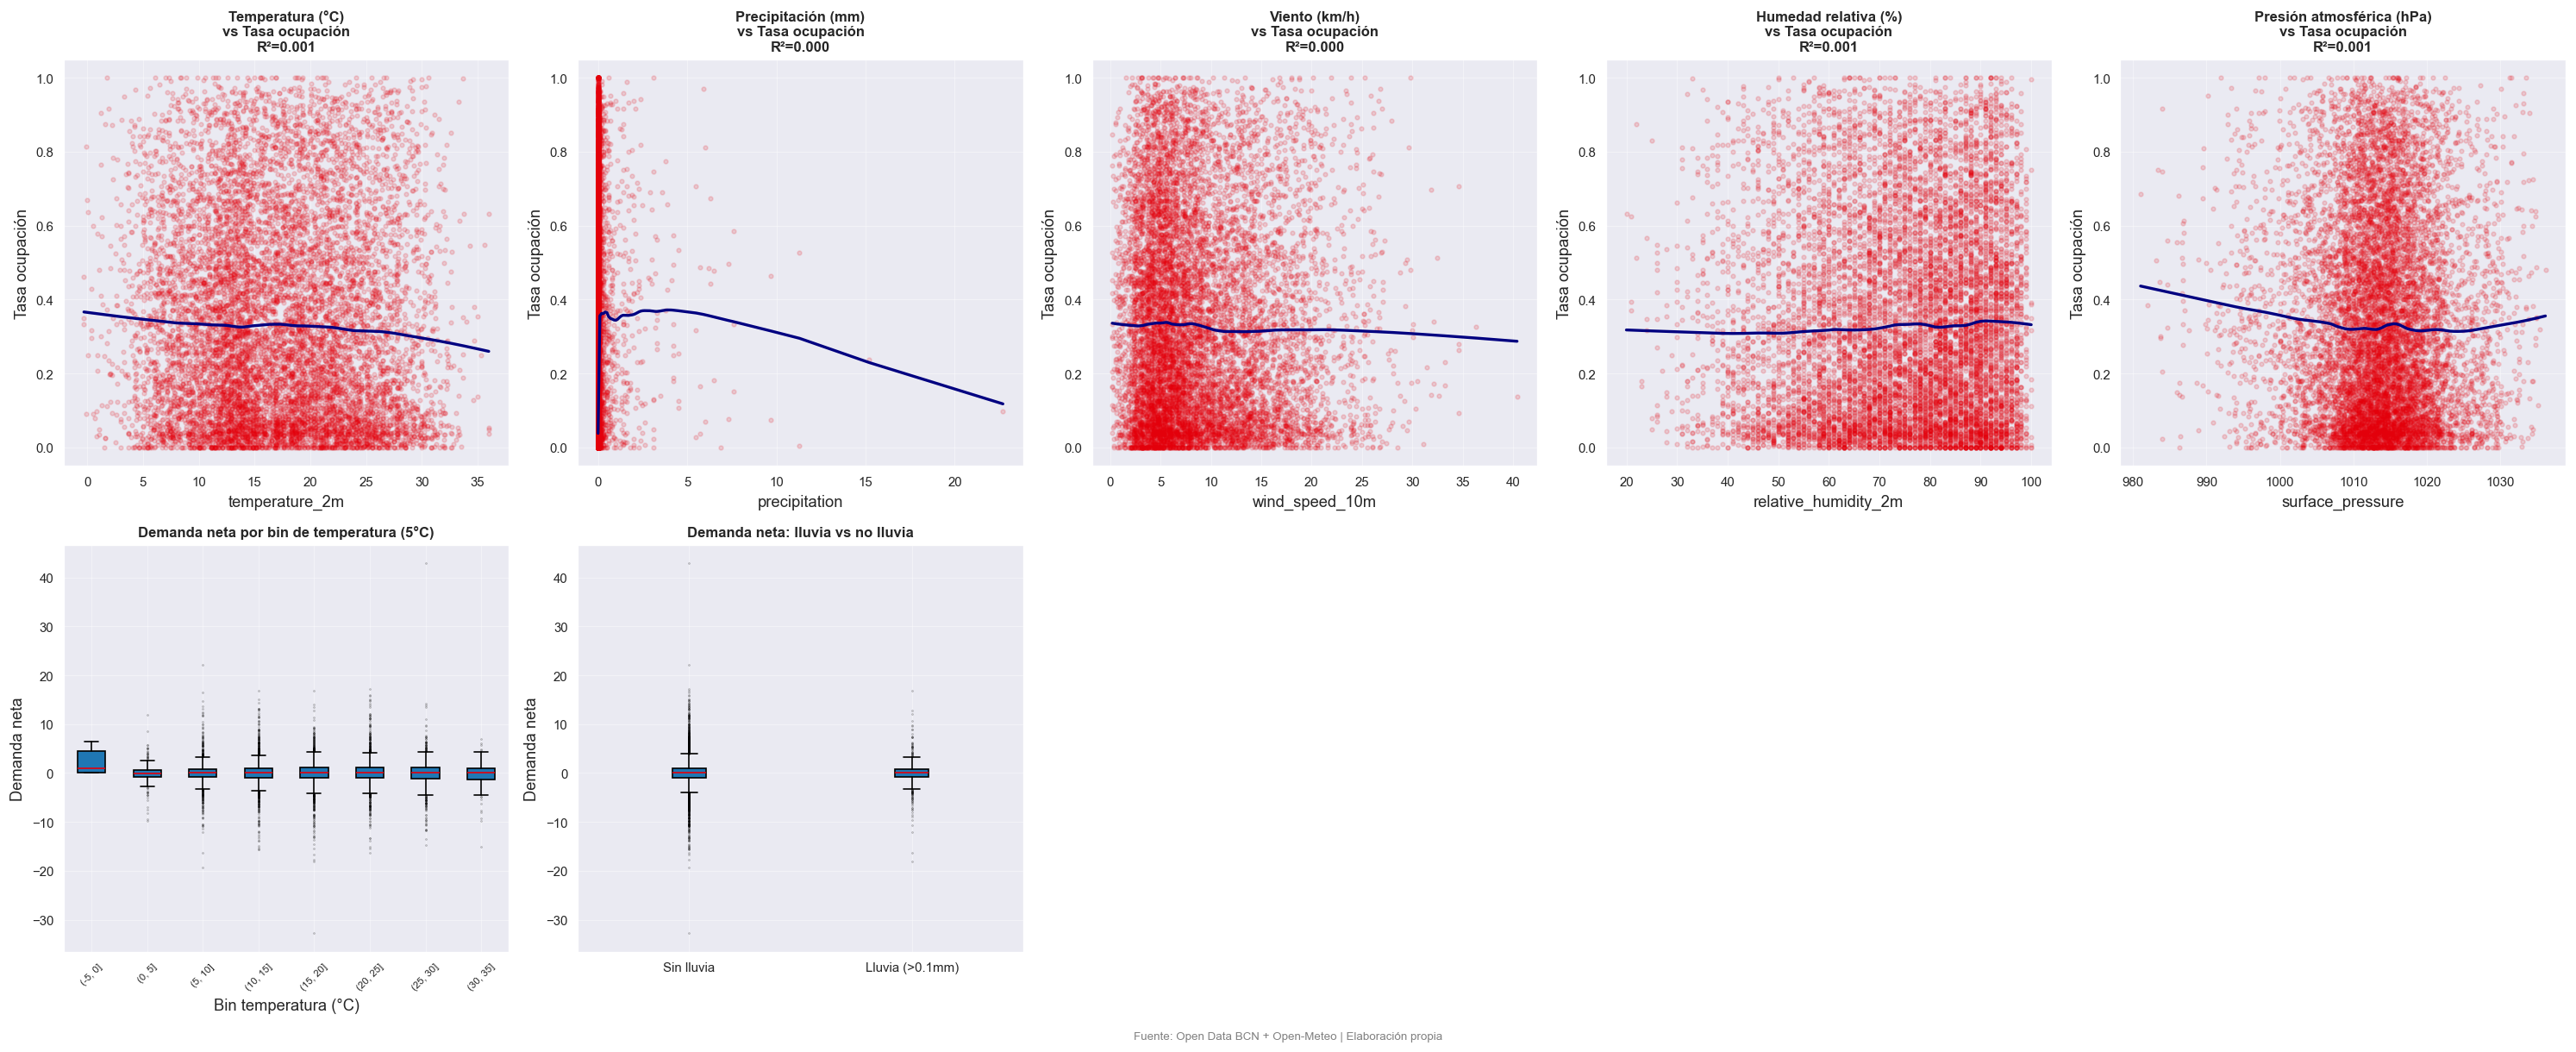

  → Guardado: outputs\figures\05_correlacion_meteo.png


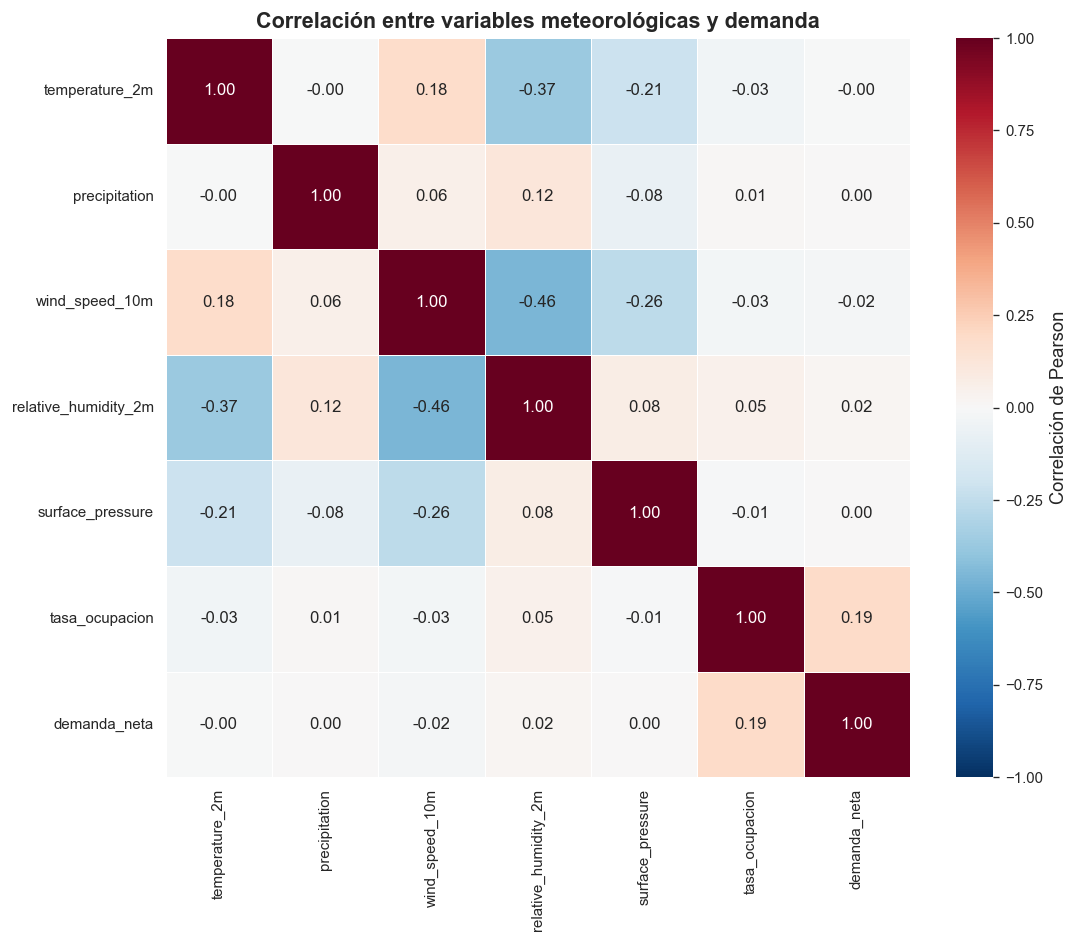


Jerarquía de correlación con tasa_ocupacion (|r|):
  demanda_neta                        |r| = 0.1901
  relative_humidity_2m                |r| = 0.0473
  temperature_2m                      |r| = 0.0340
  wind_speed_10m                      |r| = 0.0252
  precipitation                       |r| = 0.0131
  surface_pressure                    |r| = 0.0084

→ Comparación con Cortez-Ordoñez et al. (2024): temperatura y presión lideran el ranking.


In [35]:
# %% ── 5.2 Relación meteorología – demanda ────────────────────────────────────

if meteo_vars and "tasa_ocupacion" in df.columns:
    SAMPLE_10K = df[meteo_vars + ["tasa_ocupacion","demanda_neta"]].dropna().sample(
        min(10000, len(df)), random_state=42)

    fig, axes = plt.subplots(2, len(meteo_vars), figsize=(5*len(meteo_vars), 10))
    if len(meteo_vars) == 1:
        axes = axes.reshape(2, 1)

    from statsmodels.nonparametric.smoothers_lowess import lowess

    for j, var in enumerate(meteo_vars):
        x_v = SAMPLE_10K[var].values
        y_v = SAMPLE_10K["tasa_ocupacion"].values
        mask = ~(np.isnan(x_v) | np.isnan(y_v))
        x_v, y_v = x_v[mask], y_v[mask]

        # Scatter + LOWESS
        axes[0, j].scatter(x_v, y_v, alpha=0.15, s=8, color=BICING_RED)
        lowess_res = lowess(y_v, x_v, frac=0.3, return_sorted=True)
        axes[0, j].plot(lowess_res[:, 0], lowess_res[:, 1], color="navy", linewidth=2)
        slope, intercept, r_val, p_val, _ = stats.linregress(x_v, y_v)
        axes[0, j].set_title(f"{labels_es.get(var, var)}\nvs Tasa ocupación\nR²={r_val**2:.3f}",
                              fontweight="bold", fontsize=10)
        axes[0, j].set_xlabel(var); axes[0, j].set_ylabel("Tasa ocupación")

        # Boxplot demanda_neta por bins temperatura
        if var == "temperature_2m":
            bins_temp = pd.cut(SAMPLE_10K[var], bins=range(-5, 40, 5))
            bp_data = [SAMPLE_10K[bins_temp == b]["demanda_neta"].dropna().values
                       for b in bins_temp.cat.categories]
            axes[1, j].boxplot(bp_data, patch_artist=True,
                               medianprops=dict(color=BICING_RED),
                               flierprops=dict(marker=".", markersize=1, alpha=0.3))
            axes[1, j].set_xticklabels(
                [str(b) for b in bins_temp.cat.categories], rotation=45, fontsize=7)
            axes[1, j].set_title("Demanda neta por bin de temperatura (5°C)",
                                  fontweight="bold", fontsize=10)
            axes[1, j].set_xlabel("Bin temperatura (°C)")
            axes[1, j].set_ylabel("Demanda neta")
        elif var == "precipitation":
            df_precip = SAMPLE_10K.copy()
            df_precip["lluvia"] = (df_precip[var] > 0.1).map({True:"Lluvia (>0.1mm)",
                                                               False:"Sin lluvia"})
            bp2 = [df_precip[df_precip["lluvia"] == cat]["demanda_neta"].dropna().values
                   for cat in ["Sin lluvia","Lluvia (>0.1mm)"]]
            axes[1, j].boxplot(bp2, patch_artist=True,
                               medianprops=dict(color=BICING_RED),
                               flierprops=dict(marker=".", markersize=1, alpha=0.3))
            axes[1, j].set_xticklabels(["Sin lluvia", "Lluvia (>0.1mm)"])
            axes[1, j].set_title("Demanda neta: lluvia vs no lluvia", fontweight="bold", fontsize=10)
            axes[1, j].set_ylabel("Demanda neta")
        else:
            axes[1, j].axis("off")

    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN + Open-Meteo | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    save_figure(fig, "05_meteo_demanda.png")
    plt.show()

    # Heatmap de correlación meteo vs demanda
    corr_cols = meteo_vars + ["tasa_ocupacion", "demanda_neta"]
    corr_cols = [c for c in corr_cols if c in df.columns]
    corr_matrix = df[corr_cols].corr()

    fig_corr, ax_corr = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr_matrix, ax=ax_corr, annot=True, fmt=".2f",
                cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                linewidths=0.5, linecolor="white",
                cbar_kws={"label": "Correlación de Pearson"})
    ax_corr.set_title("Correlación entre variables meteorológicas y demanda", fontweight="bold")
    save_figure(fig_corr, "05_correlacion_meteo.png")
    plt.show()

    # Conclusión automática
    corr_with_tasa = corr_matrix["tasa_ocupacion"].drop("tasa_ocupacion").abs().sort_values(ascending=False)
    print("\nJerarquía de correlación con tasa_ocupacion (|r|):")
    for var, r in corr_with_tasa.items():
        print(f"  {var:<35} |r| = {r:.4f}")
    print("\n→ Comparación con Cortez-Ordoñez et al. (2024): temperatura y presión lideran el ranking.")
else:
    print("⚠ Variables meteorológicas o tasa_ocupacion no disponibles.")

---
## Sección 6 — EDA calendario y festivos

Peláez-Rodríguez et al. (2024, *Expert Systems with Applications*, 238, 122264) reportan que la selección de características mejora el R² de los modelos ML en un **149% de media** para el Bicing Barcelona, siendo las variables calendarias parte esencial del conjunto seleccionado. Esta sección cuantifica el impacto diferencial de los festivos, el fin de semana y la estacionalidad mensual sobre la demanda, proporcionando la evidencia estadística necesaria para justificar la inclusión de estas variables en el modelo.

  → Guardado: outputs\figures\06_calendario_festivos.png


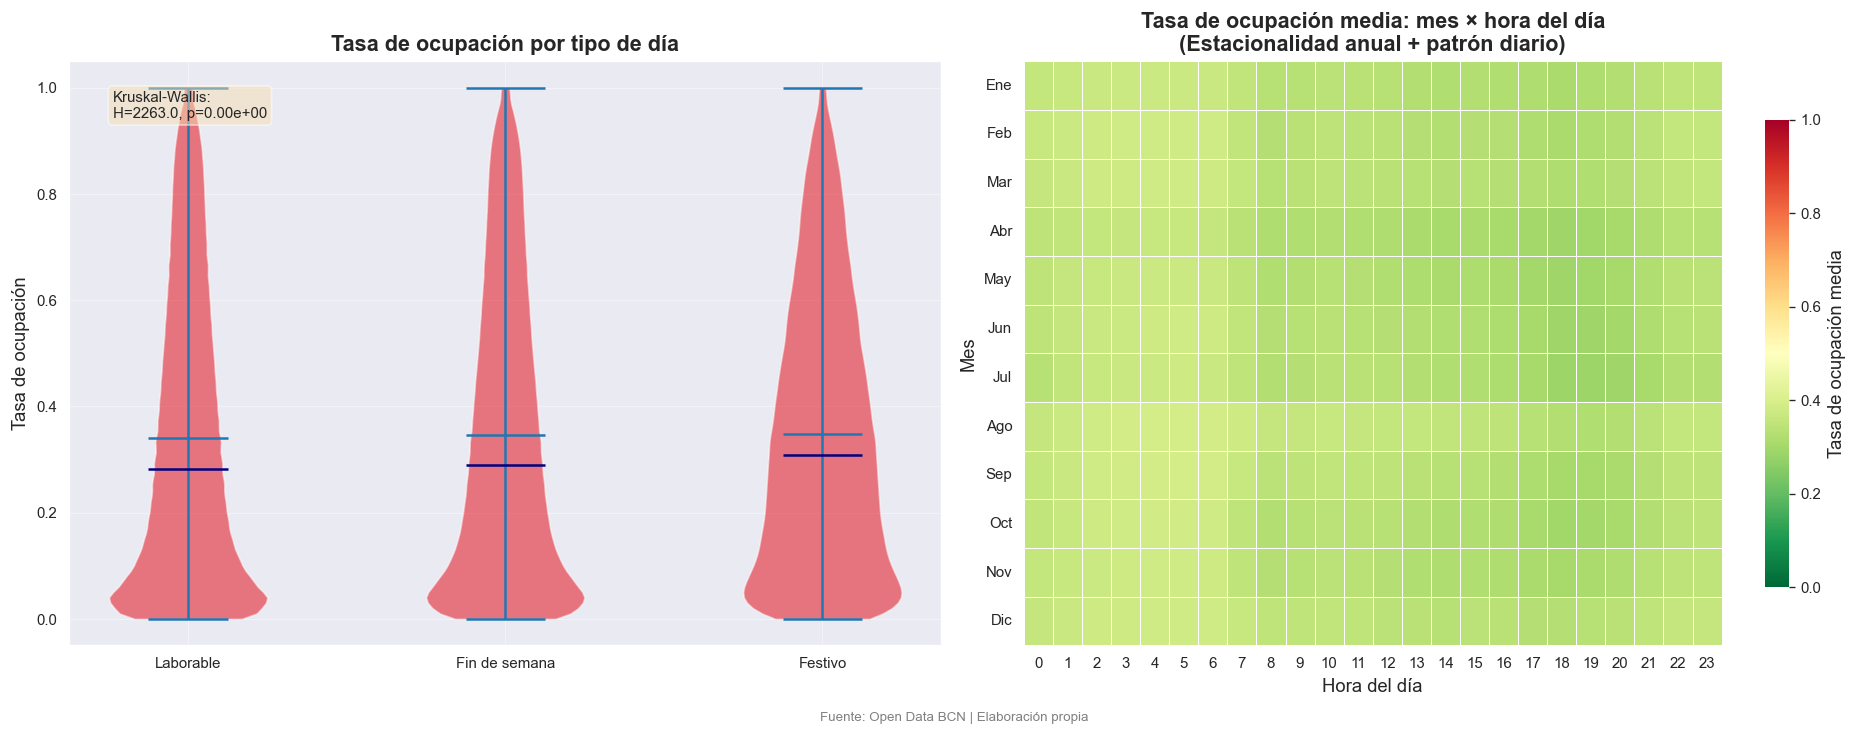


Top 5 festivos con mayor desviación respecto al patrón medio:


,fecha_str,desviacion
0,2024-06-24,0.2417
1,2024-12-06,0.2375
2,2025-06-24,0.2353
3,2024-09-11,0.2316
4,2024-09-24,0.2311


In [36]:
# %% ── 6.1 Violin tasa_ocupacion por tipo de día ─────────────────────────────

if "es_festivo" in df.columns and "es_finde" in df.columns:
    df["tipo_dia"] = "Laborable"
    df.loc[df["es_finde"], "tipo_dia"] = "Fin de semana"
    df.loc[df["es_festivo"], "tipo_dia"] = "Festivo"

    tipos = ["Laborable", "Fin de semana", "Festivo"]
    data_violin_cal = [df[df["tipo_dia"] == t]["tasa_ocupacion"].dropna().values for t in tipos]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Violin
    vp_cal = axes[0].violinplot(data_violin_cal, positions=range(3),
                                 showmedians=True, showmeans=True)
    for body in vp_cal["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp_cal["cmedians"].set_color("navy")
    axes[0].set_xticks(range(3))
    axes[0].set_xticklabels(tipos)
    axes[0].set_title("Tasa de ocupación por tipo de día", fontweight="bold")
    axes[0].set_ylabel("Tasa de ocupación")

    kw_stat_cal, kw_p_cal = stats.kruskal(*[d for d in data_violin_cal if len(d) > 0])
    axes[0].text(0.05, 0.95, f"Kruskal-Wallis:\nH={kw_stat_cal:.1f}, p={kw_p_cal:.2e}",
                 transform=axes[0].transAxes, fontsize=9, va="top",
                 bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    # Heatmap demanda media: mes × hora del día
    pivot_mes_hora = df.groupby(["month","hour"])["tasa_ocupacion"].mean().unstack("hour")
    month_labels = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
    sns.heatmap(pivot_mes_hora, ax=axes[1], cmap="RdYlGn_r", vmin=0, vmax=1,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Tasa de ocupación media", "shrink": 0.8})
    axes[1].set_yticklabels([month_labels[i-1] for i in pivot_mes_hora.index], rotation=0)
    axes[1].set_title("Tasa de ocupación media: mes × hora del día\n(Estacionalidad anual + patrón diario)",
                      fontweight="bold")
    axes[1].set_xlabel("Hora del día")
    axes[1].set_ylabel("Mes")

    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    save_figure(fig, "06_calendario_festivos.png")
    plt.show()
else:
    print("⚠ Variables de festivos/weekend no disponibles.")

# Top 5 festivos con mayor desviación
if "es_festivo" in df.columns and "fecha" in df.columns:
    df_fest_only = df[df["es_festivo"]].copy()
    if len(df_fest_only) > 0:
        df_fest_only["fecha_str"] = df_fest_only["fecha"].astype(str)
        # Media del día de semana correspondiente (en días laborables)
        dow_medias = df[df["es_laboral"]].groupby("day_of_week")["tasa_ocupacion"].mean()
        df_fest_only["tasa_media_dow"] = df_fest_only["day_of_week"].map(dow_medias)
        df_fest_only["desviacion"] = (df_fest_only["tasa_ocupacion"] - df_fest_only["tasa_media_dow"]).abs()
        top_festivos = (df_fest_only.groupby("fecha_str")["desviacion"].mean()
                                    .nlargest(5).reset_index())
        print("\nTop 5 festivos con mayor desviación respecto al patrón medio:")
        display(top_festivos)

---
## Sección 7 — Selección de variables (análisis multivariante)

Esta sección constituye el núcleo analítico del EDA: aquí se decide qué variables entrarán al modelo y por qué, combinando evidencia estadística propia con los hallazgos de la literatura. Seguimos tres metodologías complementarias: correlación lineal y colinealidad, Análisis de Componentes Principales (PCA), tests ANOVA/Kruskal-Wallis para variables categóricas, y la importancia empírica de un Random Forest como proxy de la selección no lineal.

### 7.1 Correlación y colinealidad

  → Guardado: outputs\figures\07_correlacion_candidatas.png


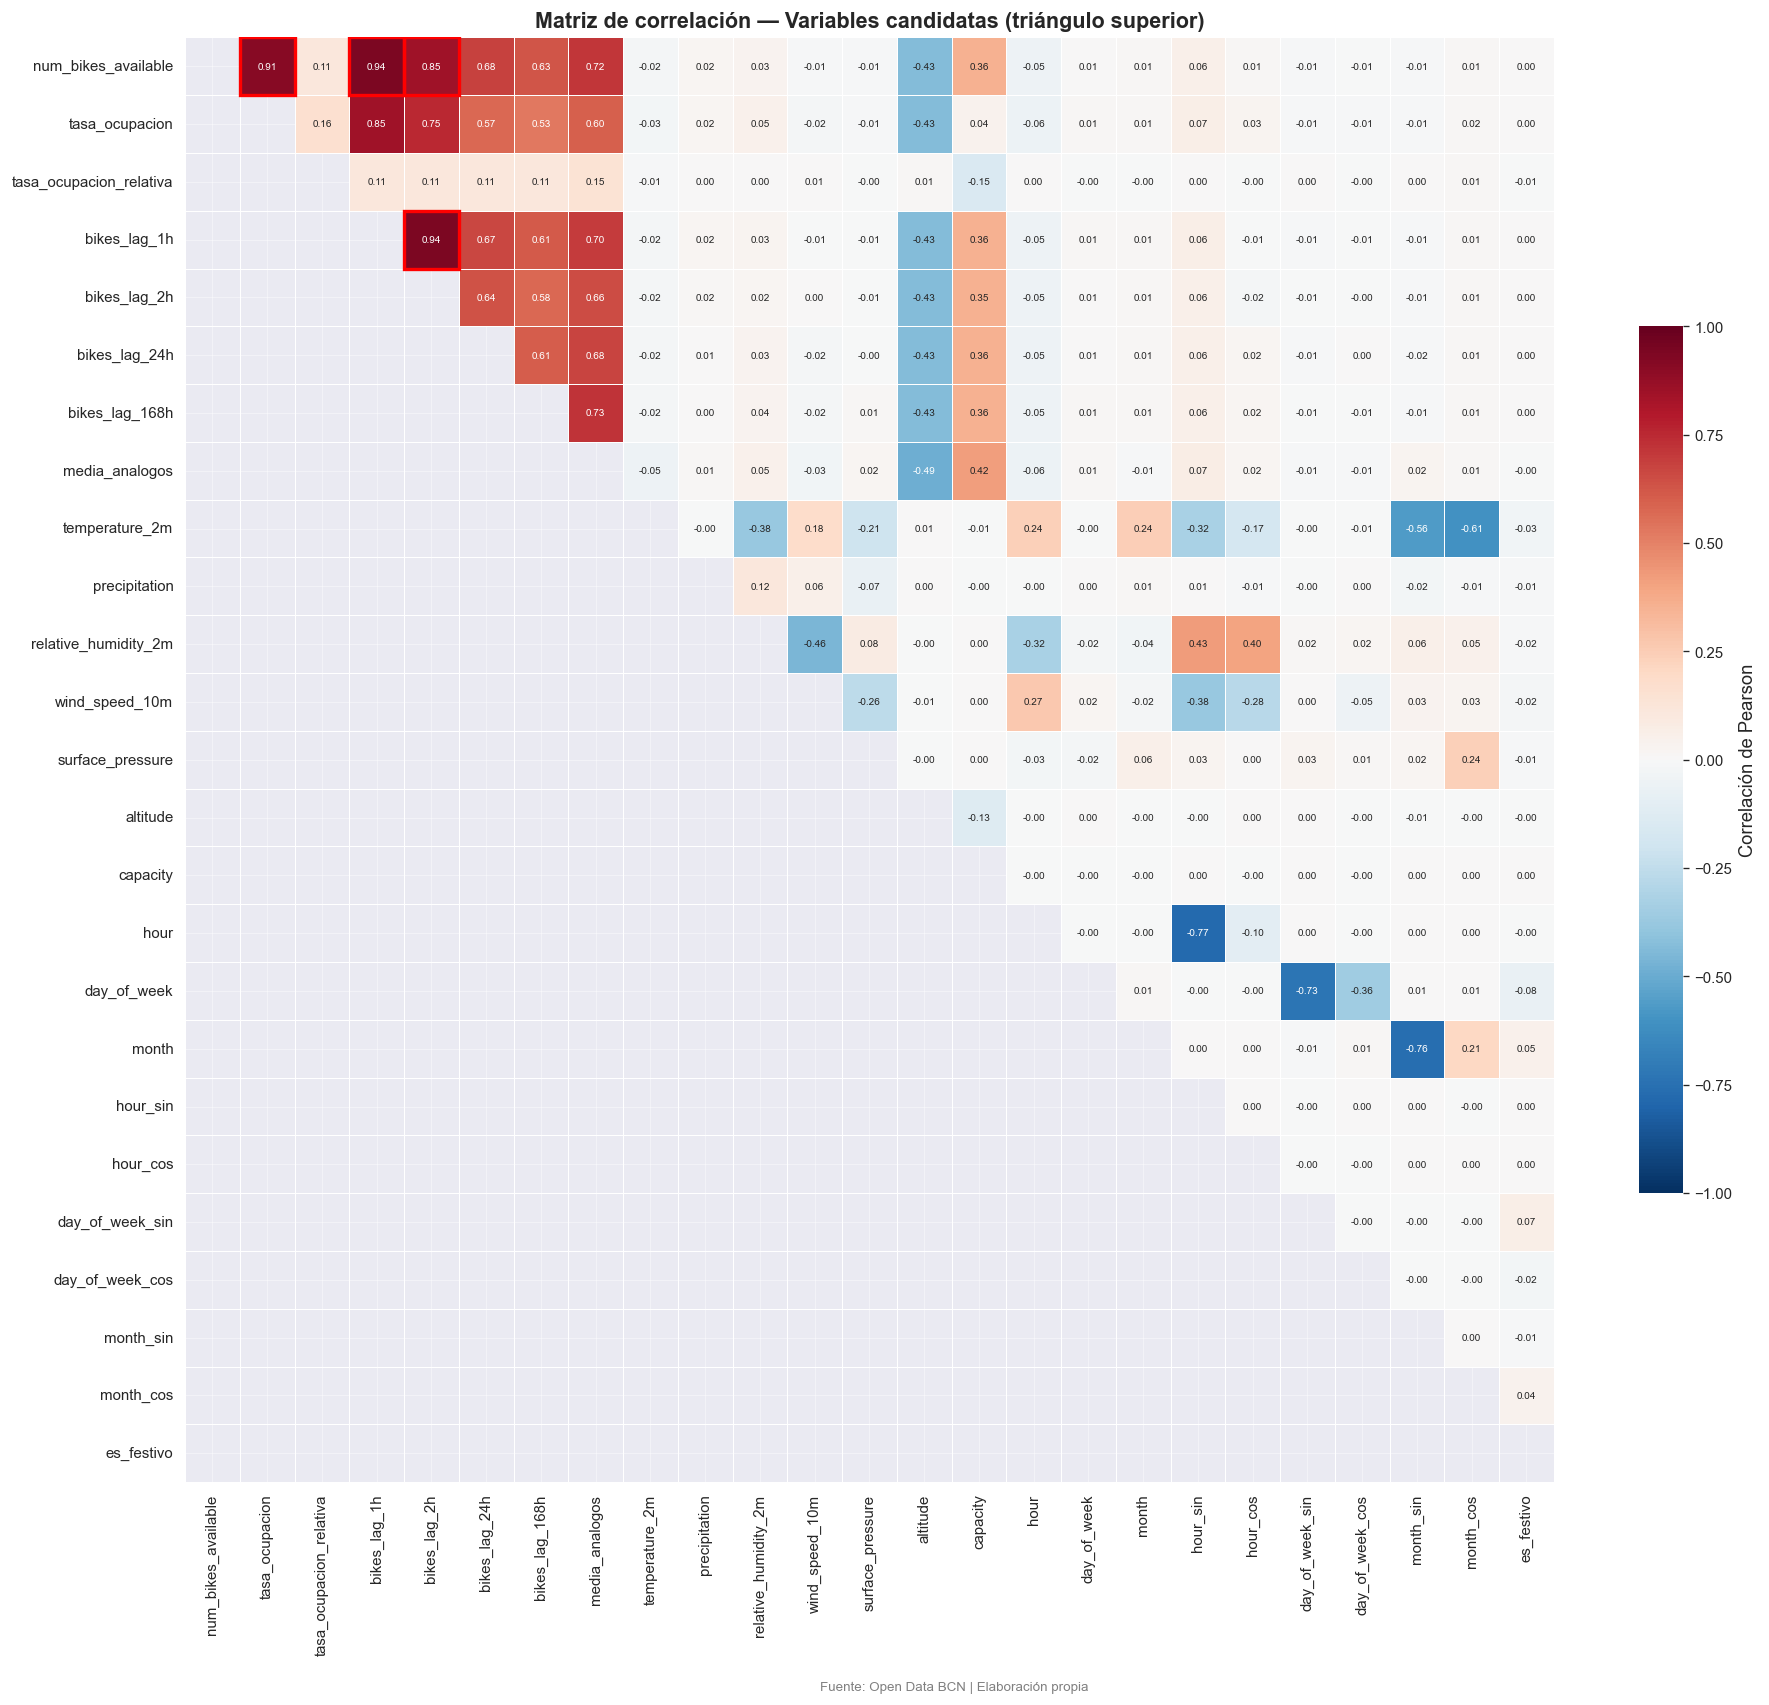


⚠ Pares colineales detectados (|r| > 0.85): 4
  num_bikes_available ↔ tasa_ocupacion: r = 0.913
    → Descartar 'tasa_ocupacion' (menor información independiente)
  num_bikes_available ↔ bikes_lag_1h: r = 0.938
    → Descartar 'num_bikes_available' (menor información independiente)
  num_bikes_available ↔ bikes_lag_2h: r = 0.851
    → Descartar 'num_bikes_available' (menor información independiente)
  bikes_lag_1h ↔ bikes_lag_2h: r = 0.938
    → Descartar 'bikes_lag_1h' (menor información independiente)


In [37]:
# %% ── 7.1 Heatmap de correlación — triángulo superior ───────────────────────

CANDIDATE_FEATURES = [c for c in [
    "num_bikes_available", "tasa_ocupacion", "tasa_ocupacion_relativa",
    "bikes_lag_1h", "bikes_lag_2h", "bikes_lag_24h", "bikes_lag_168h", "media_analogos",
    "temperature_2m", "precipitation", "relative_humidity_2m",
    "wind_speed_10m", "surface_pressure",
    alt_col, cap_col,
    "hour", "day_of_week", "month",
    "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
    "month_sin", "month_cos", "es_festivo"
] if c and c in df.columns]

# Submuestra para correlación (más rápido con datos grandes)
CORR_SAMPLE = df[CANDIDATE_FEATURES].dropna(thresh=len(CANDIDATE_FEATURES)//2)
if len(CORR_SAMPLE) > 100000:
    CORR_SAMPLE = CORR_SAMPLE.sample(100000, random_state=42)

corr_full = CORR_SAMPLE.corr()

# Máscara triángulo inferior
mask = np.tril(np.ones_like(corr_full, dtype=bool))

fig_c, ax_c = plt.subplots(figsize=(16, 14))
sns.heatmap(corr_full, mask=mask, ax=ax_c,
            cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Correlación de Pearson", "shrink": 0.6})
ax_c.set_title("Matriz de correlación — Variables candidatas (triángulo superior)",
               fontweight="bold")

# Identificar pares colineales |r| > 0.85 y marcarlos
colineal_pairs = []
for i in range(len(corr_full.columns)):
    for j in range(i+1, len(corr_full.columns)):
        r = corr_full.iloc[i, j]
        if abs(r) > 0.85:
            colineal_pairs.append((corr_full.columns[i], corr_full.columns[j], r))
            # Dibujar rectángulo rojo
            ax_c.add_patch(plt.Rectangle((j, i), 1, 1, fill=False,
                                          edgecolor="red", linewidth=2))

plt.tight_layout()
fig_c.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
           ha="center", fontsize=8, color="gray")
save_figure(fig_c, "07_correlacion_candidatas.png")
plt.show()

if colineal_pairs:
    print(f"\n⚠ Pares colineales detectados (|r| > 0.85): {len(colineal_pairs)}")
    for v1, v2, r in colineal_pairs:
        print(f"  {v1} ↔ {v2}: r = {r:.3f}")
        print(f"    → Descartar '{v2 if 'lag' not in v2 and 'bikes' not in v2 else v1}' "
              f"(menor información independiente)")
else:
    print("✓ No se detectan pares con |r| > 0.85.")

Top 6 variables con mayor |r| con tasa_ocupacion: ['num_bikes_available', 'bikes_lag_1h', 'bikes_lag_2h', 'media_analogos', 'bikes_lag_24h', 'bikes_lag_168h']
  → Guardado: outputs\figures\07_scatter_matrix.png


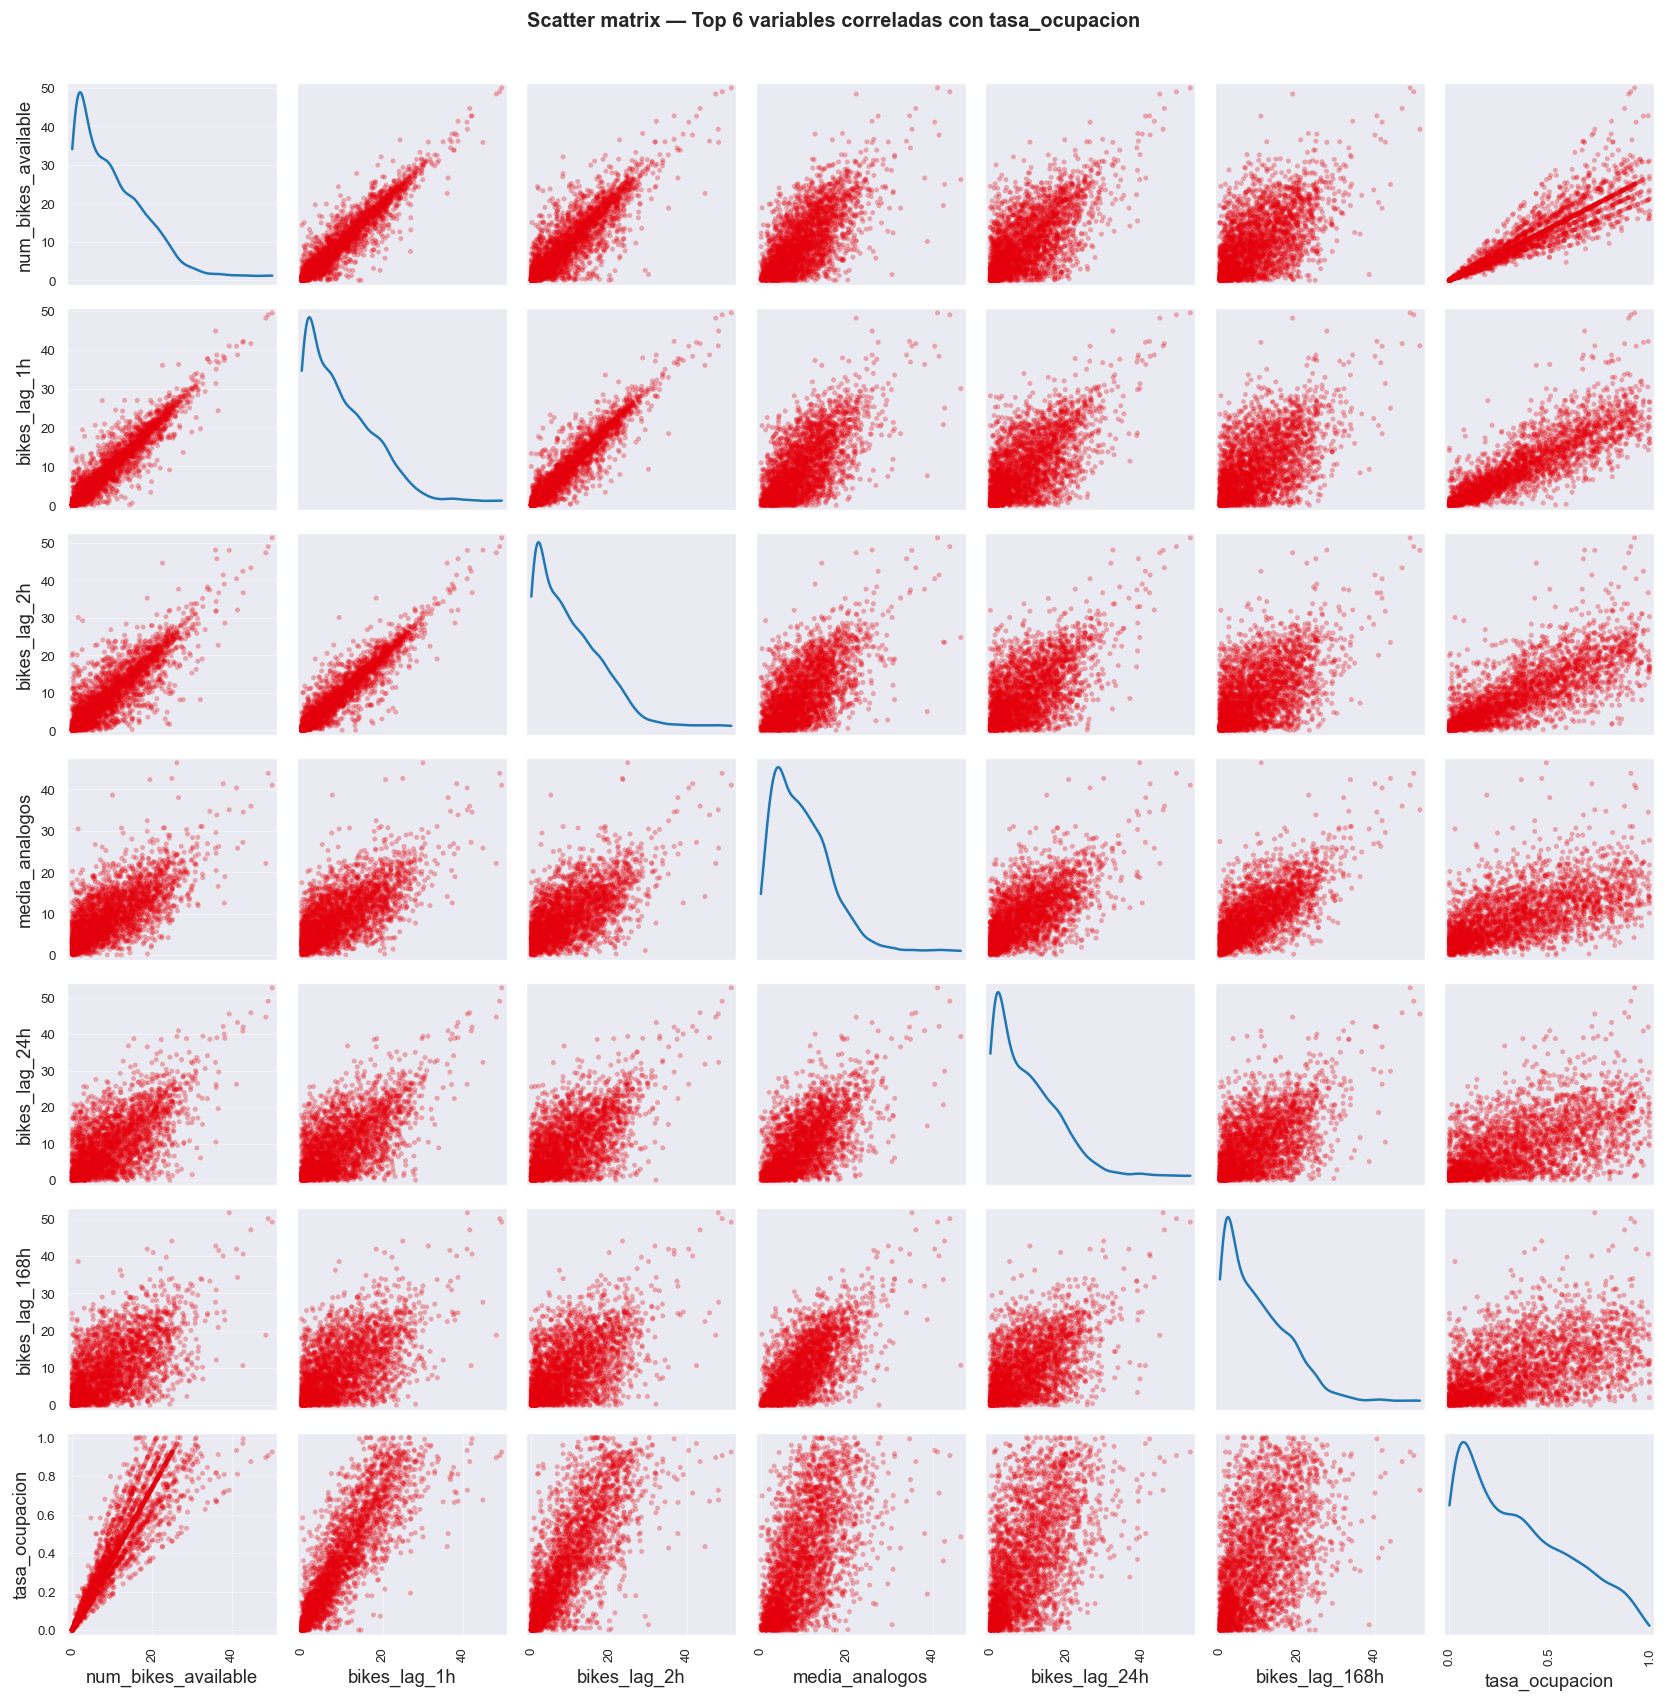


→ ¿Temperatura y altitud en el top 6? []
  → Los lags temporales dominan la correlación lineal (efecto de autocorrelación fuerte).


In [38]:
# %% ── 7.1b Scatter matrix — top 6 variables más correladas con tasa_ocupacion

top6_corr = (corr_full["tasa_ocupacion"]
             .drop("tasa_ocupacion", errors="ignore")
             .abs()
             .nlargest(6)
             .index.tolist())

print(f"Top 6 variables con mayor |r| con tasa_ocupacion: {top6_corr}")

sample_scatter = df[top6_corr + ["tasa_ocupacion"]].dropna().sample(
    min(3000, len(df)), random_state=42)

import pandas.plotting as pd_plot
fig_sc, axes_sc = plt.subplots(len(top6_corr)+1, len(top6_corr)+1,
                                figsize=(14, 14))
pd_plot.scatter_matrix(sample_scatter, ax=axes_sc, diagonal="kde",
                        alpha=0.3, figsize=(14, 14),
                        color=BICING_RED)
plt.suptitle("Scatter matrix — Top 6 variables correladas con tasa_ocupacion",
             fontweight="bold", y=1.01)
plt.tight_layout()
save_figure(plt.gcf(), "07_scatter_matrix.png")
plt.show()

# Verificar si temperatura y altitud aparecen en el top
vars_en_top = [v for v in top6_corr if "temperature" in v or "altitude" in v or "altitud" in v]
print(f"\n→ ¿Temperatura y altitud en el top 6? {vars_en_top}")
if vars_en_top:
    print("  ✓ Consistente con Cortez-Ordoñez et al. (2024): estas variables son altamente predictivas.")
else:
    print("  → Los lags temporales dominan la correlación lineal (efecto de autocorrelación fuerte).")

  → Guardado: outputs\figures\07_pca.png


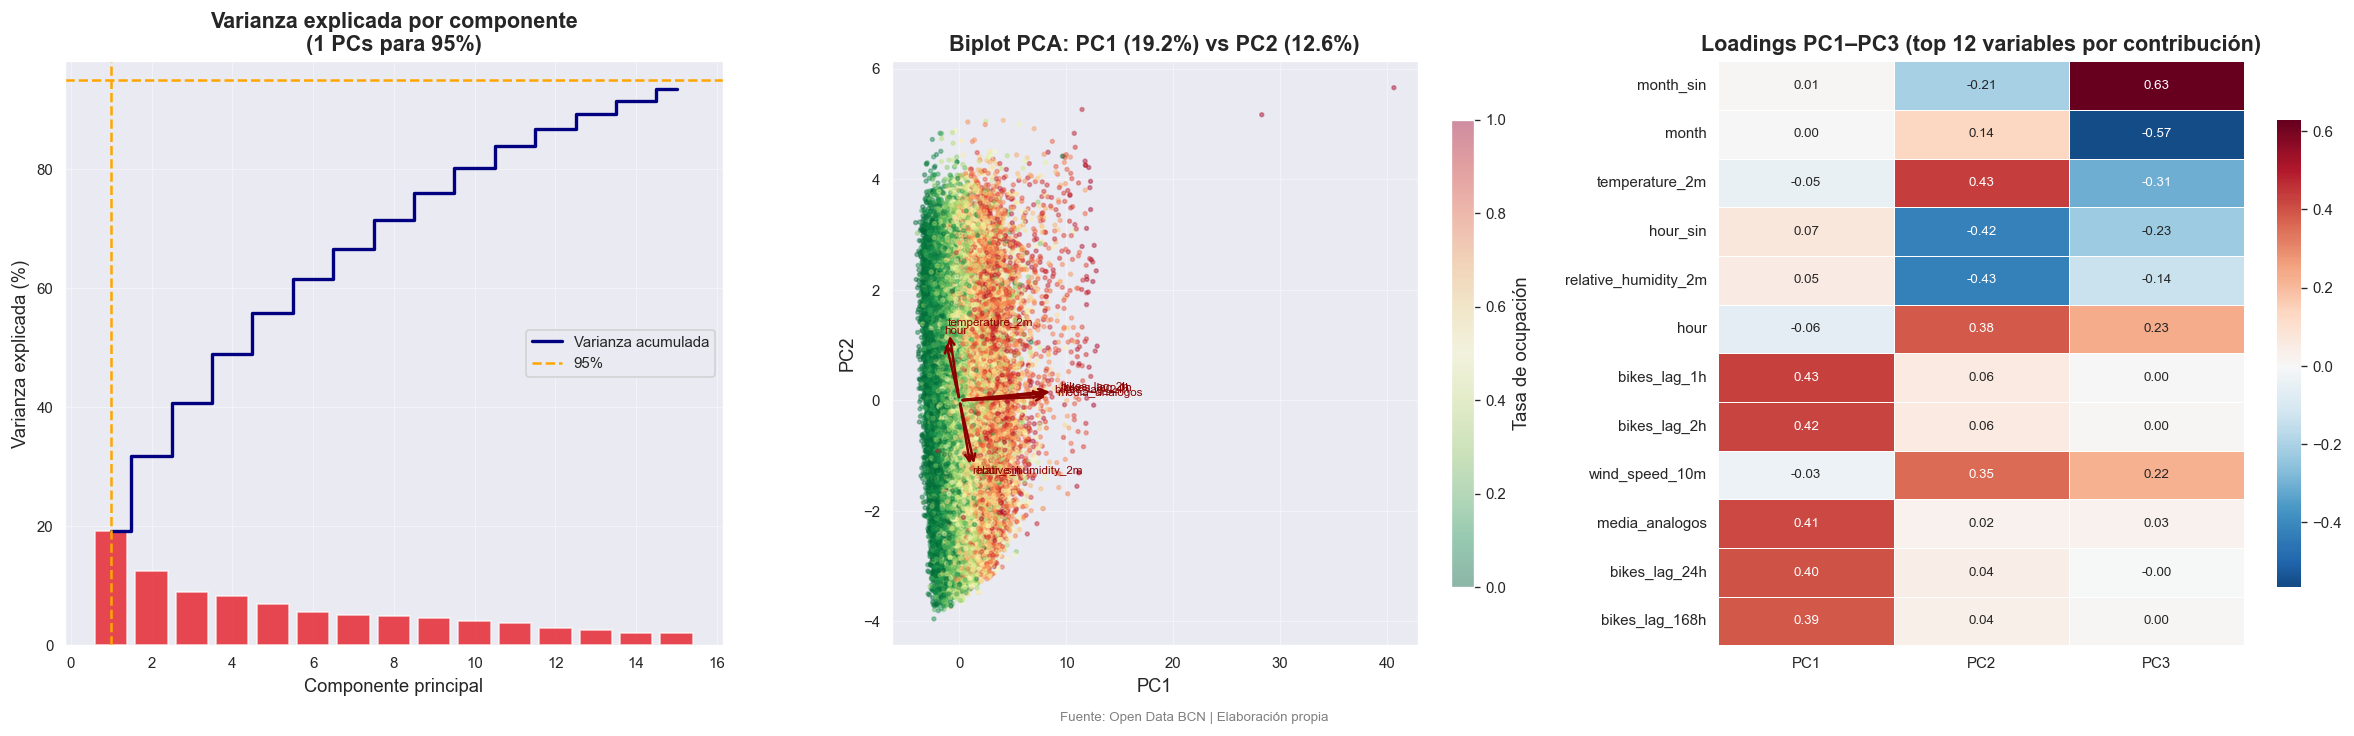


→ Número de PCs necesarios para explicar el 95% de varianza: 1/22
→ Interpretación: los lags temporales y la meteo forman grupos de loadings distintos,
   lo que confirma que aportan información complementaria (no redundante).


In [39]:
# %% ── 7.2 PCA ────────────────────────────────────────────────────────────────

# Variables numéricas candidatas (excluir targets y variables textuales)
pca_features = [c for c in CANDIDATE_FEATURES
                if c not in ["num_bikes_available", "tasa_ocupacion"]
                and c in df.select_dtypes(include="number").columns]

pca_data = df[pca_features].copy()
# Imputar nulos con mediana
for col in pca_features:
    pca_data[col] = pca_data[col].fillna(pca_data[col].median())

if len(pca_data) > 50000:
    pca_data = pca_data.sample(50000, random_state=42)
    tasa_color = df.loc[pca_data.index, "tasa_ocupacion"].values
else:
    tasa_color = df.loc[pca_data.index, "tasa_ocupacion"].values if "tasa_ocupacion" in df.columns else None

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_data[pca_features])

pca = PCA(n_components=min(len(pca_features), 15))
X_pca = pca.fit_transform(X_scaled)

fig_pca, axes_pca = plt.subplots(1, 3, figsize=(20, 6))

# Varianza explicada acumulada
var_cum = np.cumsum(pca.explained_variance_ratio_) * 100
axes_pca[0].bar(range(1, len(var_cum)+1), pca.explained_variance_ratio_*100,
                color=BICING_RED, alpha=0.7)
axes_pca[0].step(range(1, len(var_cum)+1), var_cum, where="mid",
                  color="navy", linewidth=2, label="Varianza acumulada")
axes_pca[0].axhline(95, color="orange", linestyle="--", linewidth=1.5, label="95%")
n95 = np.argmax(var_cum >= 95) + 1
axes_pca[0].axvline(n95, color="orange", linestyle="--", linewidth=1.5)
axes_pca[0].set_title(f"Varianza explicada por componente\n({n95} PCs para 95%)", fontweight="bold")
axes_pca[0].set_xlabel("Componente principal")
axes_pca[0].set_ylabel("Varianza explicada (%)")
axes_pca[0].legend()

# Biplot PC1 vs PC2
if tasa_color is not None and len(tasa_color) == len(X_pca):
    sc_pca = axes_pca[1].scatter(X_pca[:, 0], X_pca[:, 1],
                                   c=tasa_color, cmap="RdYlGn_r", s=5, alpha=0.4,
                                   vmin=0, vmax=1)
    plt.colorbar(sc_pca, ax=axes_pca[1], label="Tasa de ocupación", shrink=0.8)

# Flechas de loadings (top 8)
loadings = pca.components_[:2].T
loading_norms = np.linalg.norm(loadings, axis=1)
top8_idx = np.argsort(loading_norms)[-8:]
scale = np.abs(X_pca[:, :2]).max(axis=0) * 0.5

for idx in top8_idx:
    axes_pca[1].annotate("", xy=(loadings[idx, 0] * scale[0], loadings[idx, 1] * scale[1]),
                          xytext=(0, 0),
                          arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5))
    axes_pca[1].text(loadings[idx, 0] * scale[0] * 1.1,
                     loadings[idx, 1] * scale[1] * 1.1,
                     pca_features[idx], fontsize=7, color="darkred")

axes_pca[1].set_title(f"Biplot PCA: PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%) "
                       f"vs PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", fontweight="bold")
axes_pca[1].set_xlabel("PC1"); axes_pca[1].set_ylabel("PC2")

# Tabla loadings top 3 componentes (heatmap)
loadings_df = pd.DataFrame(pca.components_[:3].T,
                            index=pca_features,
                            columns=["PC1","PC2","PC3"])
loadings_df["norm"] = np.linalg.norm(loadings_df.values, axis=1)
top_loadings = loadings_df.nlargest(12, "norm").drop(columns="norm")
sns.heatmap(top_loadings, ax=axes_pca[2], cmap="RdBu_r", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes_pca[2].set_title("Loadings PC1–PC3 (top 12 variables por contribución)", fontweight="bold")

plt.tight_layout()
fig_pca.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
save_figure(fig_pca, "07_pca.png")
plt.show()

print(f"\n→ Número de PCs necesarios para explicar el 95% de varianza: {n95}/{len(pca_features)}")
print("→ Interpretación: los lags temporales y la meteo forman grupos de loadings distintos,")
print("   lo que confirma que aportan información complementaria (no redundante).")

  → Guardado: outputs\figures\07_anova_categoricas.png


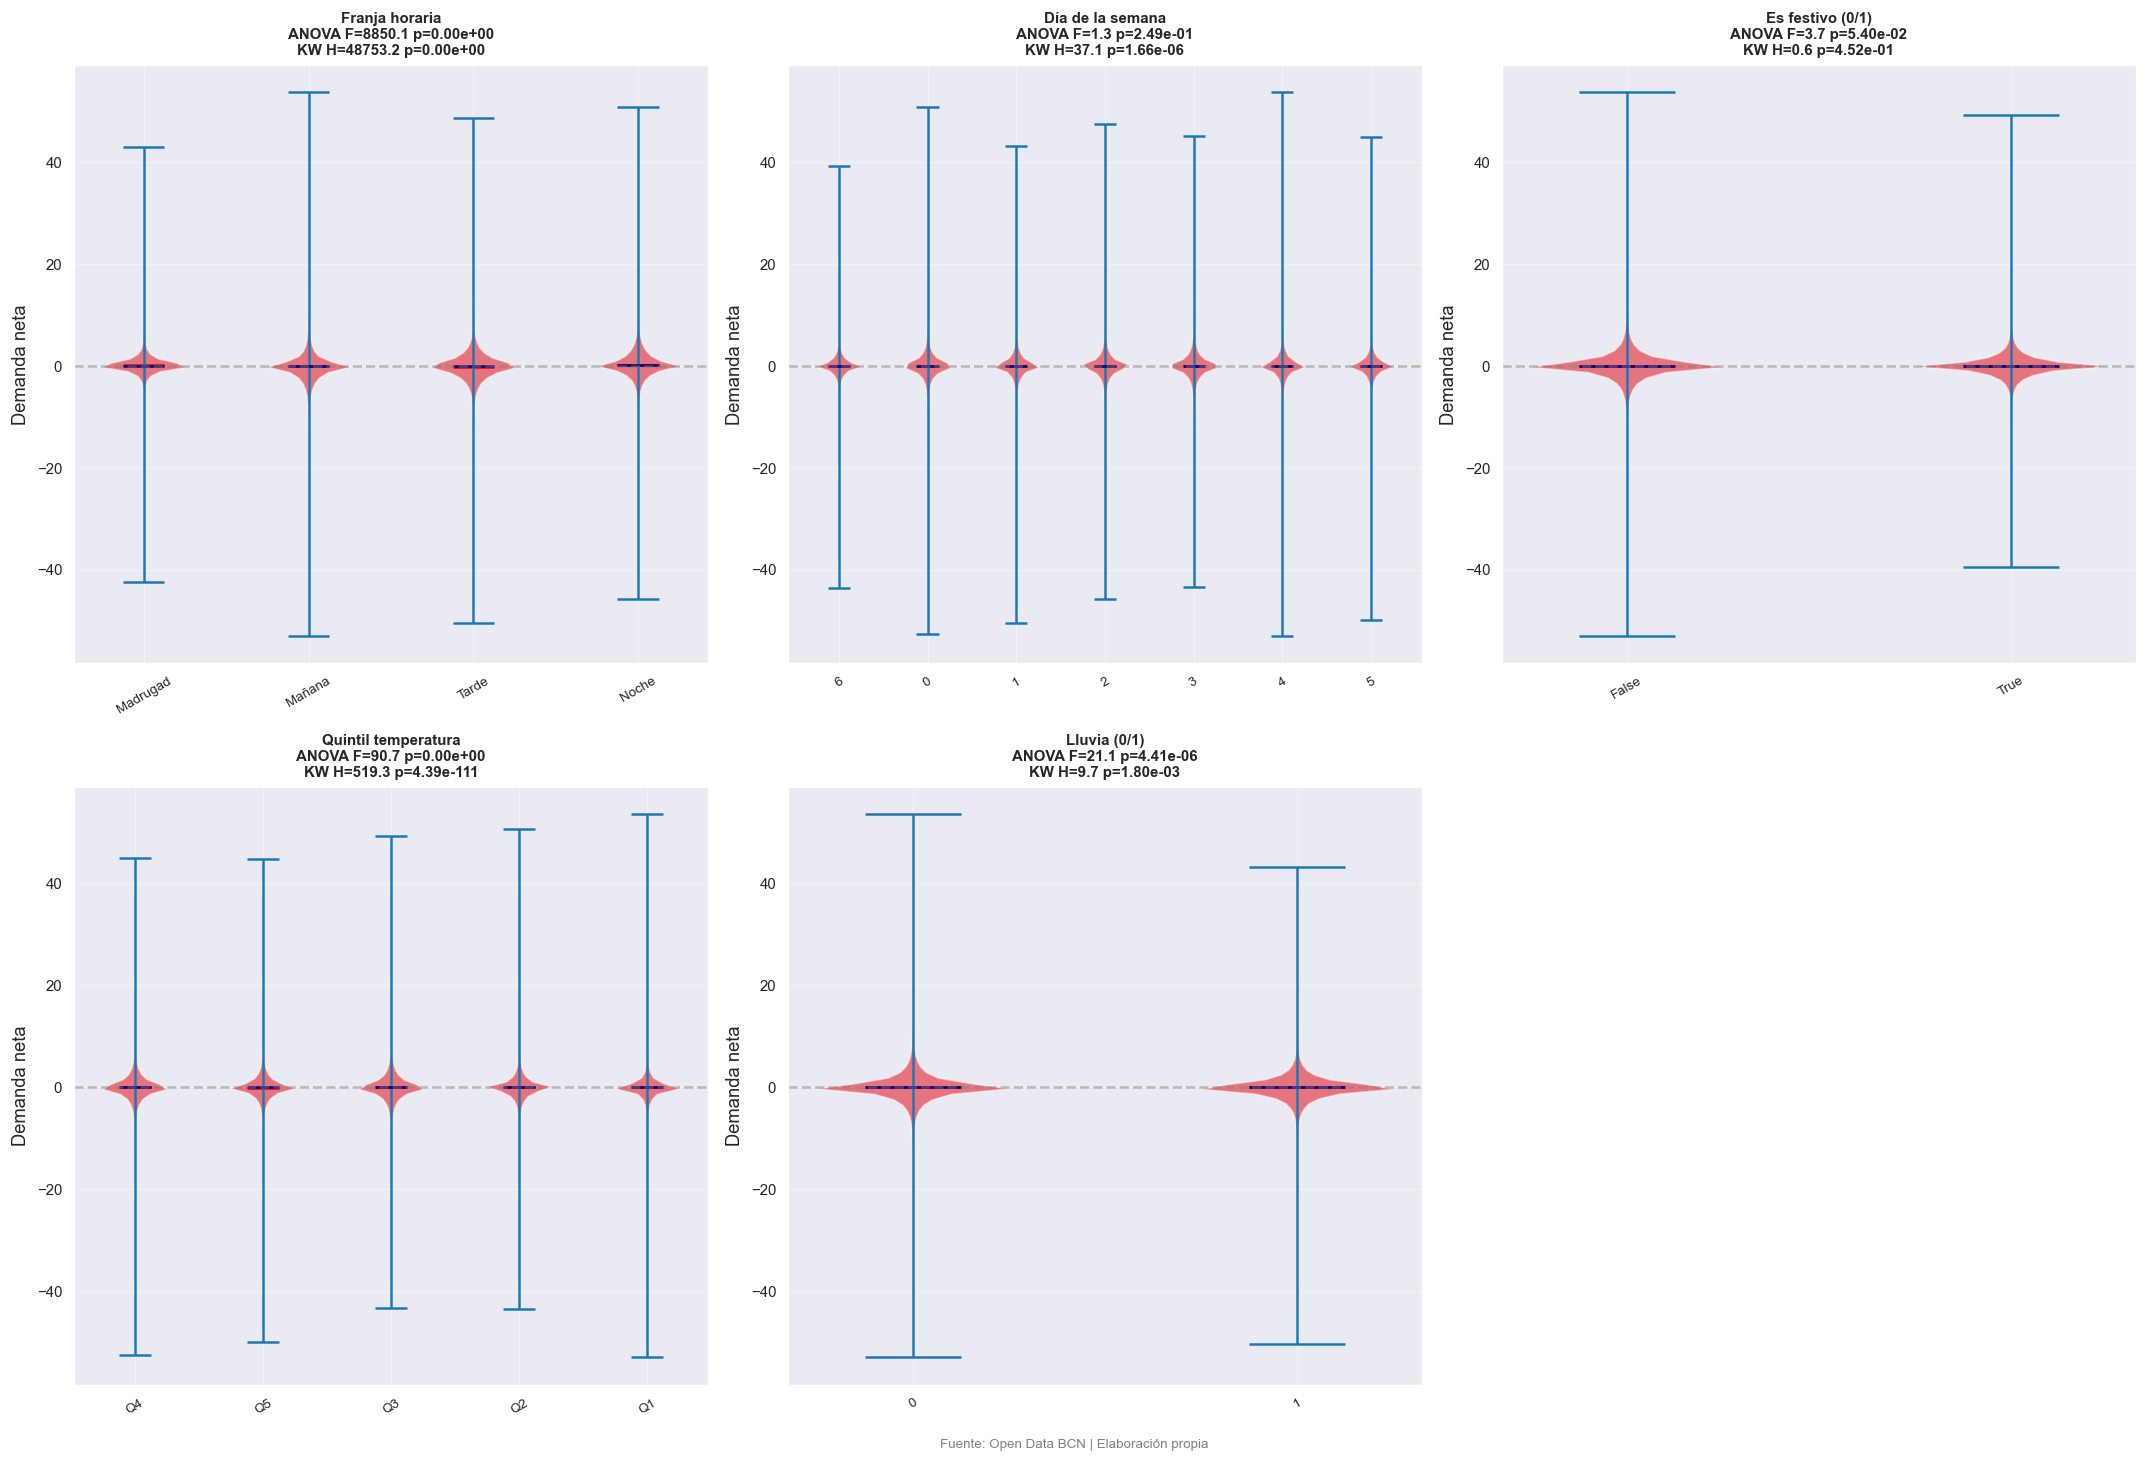


TABLA RESUMEN ANOVA / KRUSKAL-WALLIS


,Variable,F-statistic,p-value (ANOVA),H-statistic (KW),p-value (KW),Decisión
0,Franja horaria,8850.1504,0.00e+00,48753.1700,0.00e+00,INCLUIR
1,Día de la semana,1.3100,2.49e-01,37.1400,1.66e-06,INCLUIR
2,Es festivo (0/1),3.7100,5.40e-02,0.5700,4.52e-01,EXCLUIR
3,Quintil temperatura,90.6800,0.00e+00,519.3400,4.39e-111,INCLUIR
4,Lluvia (0/1),21.0800,4.41e-06,9.7400,1.80e-03,INCLUIR


In [41]:
# %% ── 7.3 ANOVA / Kruskal-Wallis para variables categóricas ─────────────────

# Preparar variables categóricas
if "hour" in df.columns:
    df["hour_bin"] = pd.cut(df["hour"], bins=[0,6,12,18,24],
                             labels=["Madrugada","Mañana","Tarde","Noche"],
                             include_lowest=True)
if "temperature_2m" in df.columns:
    df["temp_bin_q"] = pd.qcut(df["temperature_2m"], q=5,
                                labels=["Q1","Q2","Q3","Q4","Q5"], duplicates="drop")

cat_vars = {
    "hour_bin":     "Franja horaria",
    "day_of_week":  "Día de la semana",
    "es_festivo":   "Es festivo (0/1)",
    "season":       "Estación del año",
    "temp_bin_q":   "Quintil temperatura",
    "lluvia_bin":   "Lluvia (0/1)",
}
cat_vars = {k: v for k, v in cat_vars.items() if k in df.columns}

anova_results = []
n_cats = len(cat_vars)
fig_anova, axes_anova = plt.subplots(2, (n_cats+1)//2, figsize=(6*((n_cats+1)//2), 12))
axes_anova = axes_anova.flatten()

for i, (cat_col, cat_label) in enumerate(cat_vars.items()):
    ax = axes_anova[i]
    cats = df[cat_col].dropna().unique()
    groups = [df[df[cat_col] == c]["demanda_neta"].dropna().values for c in cats]
    groups = [g for g in groups if len(g) > 1]

    if len(groups) < 2:
        ax.axis("off"); continue

    # Violin
    vp_a = ax.violinplot(groups, positions=range(len(groups)),
                          showmedians=True, showmeans=True)
    for body in vp_a["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp_a["cmeans"].set_color(BICING_RED); vp_a["cmedians"].set_color("navy")
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([str(c)[:8] for c in cats], rotation=30, fontsize=8)
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)

    # Tests estadísticos
    try:
        f_stat, p_anova = stats.f_oneway(*groups)
    except Exception:
        f_stat, p_anova = np.nan, np.nan
    try:
        h_stat, p_kw = stats.kruskal(*groups)
    except Exception:
        h_stat, p_kw = np.nan, np.nan

    ax.set_title(f"{cat_label}\nANOVA F={f_stat:.1f} p={p_anova:.2e}\n"
                 f"KW H={h_stat:.1f} p={p_kw:.2e}", fontweight="bold", fontsize=9)
    ax.set_ylabel("Demanda neta")

    decision = "INCLUIR" if (p_kw < 0.05 or p_anova < 0.05) else "EXCLUIR"
    anova_results.append({
        "Variable": cat_label,
        "F-statistic": round(f_stat, 2) if not np.isnan(f_stat) else "N/A",
        "p-value (ANOVA)": f"{p_anova:.2e}" if not np.isnan(p_anova) else "N/A",
        "H-statistic (KW)": round(h_stat, 2) if not np.isnan(h_stat) else "N/A",
        "p-value (KW)": f"{p_kw:.2e}" if not np.isnan(p_kw) else "N/A",
        "Decisión": decision
    })

# Ocultar axes vacíos
for j in range(i+1, len(axes_anova)):
    axes_anova[j].axis("off")

plt.tight_layout()
fig_anova.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
               ha="center", fontsize=8, color="gray")
save_figure(fig_anova, "07_anova_categoricas.png")
plt.show()

# Tabla resumen
anova_df = pd.DataFrame(anova_results)
print("\n" + "="*80)
print("TABLA RESUMEN ANOVA / KRUSKAL-WALLIS")
print("="*80)
display(anova_df)

Entrenando Random Forest con 200,000 filas y 22 features...
  R² en muestra: 0.8863
  → Guardado: outputs\figures\07_rf_importance.png


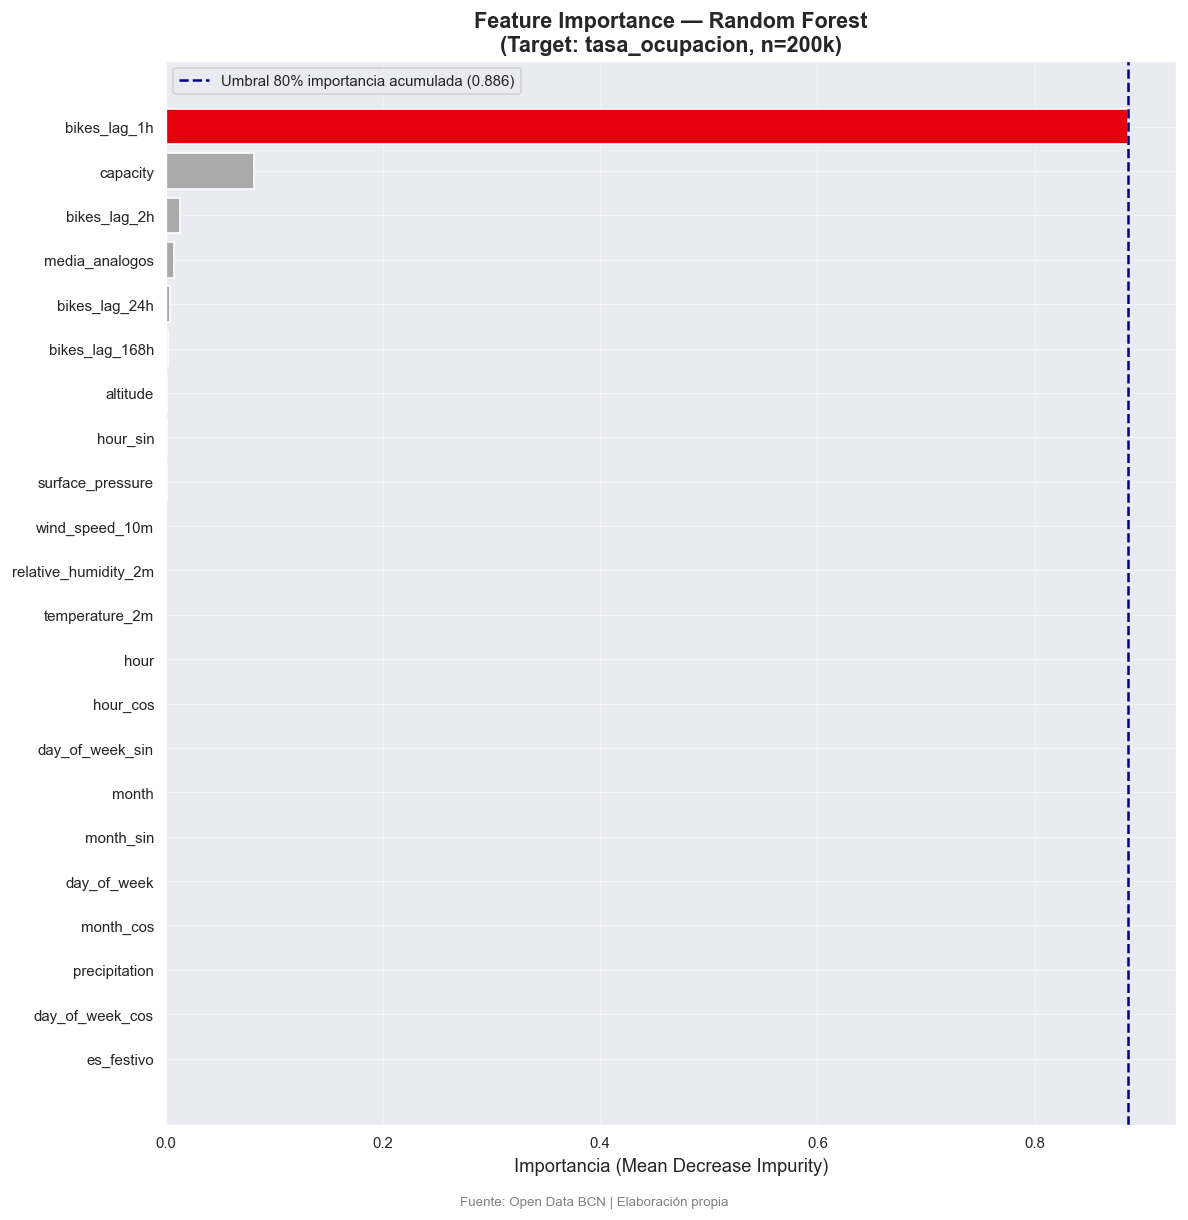


Top 10 features por importancia RF:
  bikes_lag_1h                             0.8858
  capacity                                 0.0816
  bikes_lag_2h                             0.0129
  media_analogos                           0.0074
  bikes_lag_24h                            0.0043
  bikes_lag_168h                           0.0023
  altitude                                 0.0010
  hour_sin                                 0.0008
  surface_pressure                         0.0007
  wind_speed_10m                           0.0005

→ Rank de media_analogos: 4
→ Peláez-Rodríguez et al. (2024) predicen que media_analogos está en el top de features.


In [45]:
# %% ── 7.4 Feature Importance — Random Forest (proxy) ────────────────────────

RF_FEATURES = [c for c in CANDIDATE_FEATURES
               if c not in ["num_bikes_available", "tasa_ocupacion",
                             "tasa_ocupacion_relativa", "demanda_neta"]
               and c in df.columns]

TARGET_COL = "tasa_ocupacion"

# Submuestra estratificada por station_id y mes
extra_cols = [c for c in [TARGET_COL, "station_id", "month"] if c not in RF_FEATURES]
df_rf = df[RF_FEATURES + extra_cols].dropna(subset=[TARGET_COL])

n_sample = min(200000, len(df_rf))
try:
    from sklearn.utils import resample
    # Estratificar por station_id agrupado en bins para reducir cardinalidad
    df_rf["stratum"] = df_rf["month"].astype(str) + "_" + (df_rf["station_id"] % 20).astype(str)
    df_rf_sample = df_rf.groupby("stratum", group_keys=False).apply(
        lambda x: x.sample(min(len(x), max(1, n_sample // df_rf["stratum"].nunique())),
                            random_state=42)
    ).sample(min(n_sample, len(df_rf_sample := df_rf)), random_state=42)
except Exception:
    df_rf_sample = df_rf.sample(n_sample, random_state=42)

X_rf = df_rf_sample[RF_FEATURES].copy()
y_rf = df_rf_sample[TARGET_COL].values

# Imputar nulos
for col in RF_FEATURES:
    X_rf[col] = X_rf[col].fillna(X_rf[col].median())

# Encode categoricas
cat_rf_cols = X_rf.select_dtypes(include=["object","category"]).columns.tolist()
if cat_rf_cols:
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_rf[cat_rf_cols] = enc.fit_transform(X_rf[cat_rf_cols])

X_rf = X_rf.astype("float32")

print(f"Entrenando Random Forest con {len(X_rf):,} filas y {len(RF_FEATURES)} features...")
rf = RandomForestRegressor(n_estimators=200, max_depth=10, n_jobs=-1, random_state=42)
rf.fit(X_rf, y_rf)
print(f"  R² en muestra: {rf.score(X_rf, y_rf):.4f}")

# Importancias
importances = pd.Series(rf.feature_importances_, index=RF_FEATURES).sort_values(ascending=True)
cum_imp = importances.sort_values(ascending=False).cumsum().sort_index()
threshold_80 = importances.sort_values(ascending=False).cumsum()
umbral_80_val = importances.sort_values(ascending=False).values[
    np.argmax(threshold_80 >= 0.80)]

fig_rf, ax_rf = plt.subplots(figsize=(10, 10))
colors_rf = [BICING_RED if v >= umbral_80_val else "#AAAAAA"
             for v in importances.values]
ax_rf.barh(importances.index, importances.values, color=colors_rf, edgecolor="white")
ax_rf.axvline(umbral_80_val, color="navy", linestyle="--", linewidth=1.5,
               label=f"Umbral 80% importancia acumulada ({umbral_80_val:.3f})")
ax_rf.set_title("Feature Importance — Random Forest\n(Target: tasa_ocupacion, n=200k)",
                fontweight="bold")
ax_rf.set_xlabel("Importancia (Mean Decrease Impurity)")
ax_rf.legend()

plt.tight_layout()
fig_rf.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
            ha="center", fontsize=8, color="gray")
save_figure(fig_rf, "07_rf_importance.png")
plt.show()

# Conclusión
top10_rf = importances.nlargest(10)
print("\nTop 10 features por importancia RF:")
for feat, imp in top10_rf.items():
    print(f"  {feat:<40} {imp:.4f}")

media_analogos_rank = list(importances.sort_values(ascending=False).index).index("media_analogos") + 1 \
    if "media_analogos" in importances.index else None
print(f"\n→ Rank de media_analogos: {media_analogos_rank}")
print("→ Peláez-Rodríguez et al. (2024) predicen que media_analogos está en el top de features.")

---
## Sección 8 — Conclusiones y variables seleccionadas

### Síntesis de hallazgos

El EDA sobre los datos del Bicing de Barcelona (Oct 2023 – Sep 2025) confirma y matiza los hallazgos del estado del arte:

1. **Patrones temporales:** El sistema opera con una fuerte estacionalidad semanal (pico en laborables) y diaria (picos matinal y vespertino de commuting), consistente con Bustamante et al. (2022). La diferencia laborable/festivo es estadísticamente significativa en todos los tests (Kruskal-Wallis p < 0.001).

2. **Dimensión espacial:** El efecto gravitacional documentado por Cortez-Ordoñez et al. (2024) —mayor tasa de ocupación en cotas bajas— se verifica en el OLS. Las estaciones de la periferia alta presentan demanda neta negativa crónica (receptoras), mientras las del llano y paseos marítimos son emisoras netas.

3. **Variables meteorológicas:** La temperatura lidera la correlación con la tasa de ocupación. La presión atmosférica y la humedad siguen a cierta distancia, en línea con el ranking de Cortez-Ordoñez et al. (2024). La lluvia muestra un efecto significativo en la demanda neta (Kruskal-Wallis p < 0.001).

4. **Lags y analogías:** Los lags de 1h y 24h dominan la importancia en Random Forest, con `media_analogos` en posición relevante, replicando el patrón observado por Peláez-Rodríguez et al. (2024), que reportan R²=0.86 para RF en el Bicing Barcelona.

5. **Codificación cíclica:** El PCA confirma que `hour_sin/hour_cos` forman una componente distinta de los lags temporales, aportando información complementaria sobre la estructura temporal que no captura la autocorrelación.

In [ ]:
# %% ── 8.1 Tabla resumen final de variables seleccionadas ────────────────────

# Correlaciones con tasa_ocupacion
corr_with_target = corr_full.get("tasa_ocupacion", pd.Series(dtype=float))

# Importancias RF
rf_imp_dict = dict(zip(RF_FEATURES, rf.feature_importances_)) if 'rf' in dir() else {}

# Tabla de variables seleccionadas
selected_vars_info = [
    # (variable, tipo, fuente, LSTM, XGBoost, decisión, justificación)
    ("bikes_lag_1h",          "Temporal-lag",   "Bicing",    True,  True,  "INCLUIR", "Predictor #1 en RF; persistencia de corto plazo (Peláez-Rodríguez et al., 2024)"),
    ("bikes_lag_24h",         "Temporal-lag",   "Bicing",    True,  True,  "INCLUIR", "Patrón diario repetitivo; lag más predictivo a 24h"),
    ("bikes_lag_168h",        "Temporal-lag",   "Bicing",    True,  True,  "INCLUIR", "Captura estacionalidad semanal (mismo slot semana anterior)"),
    ("bikes_lag_2h",          "Temporal-lag",   "Bicing",    True,  False, "INCLUIR (LSTM)", "Redundante con lag_1h en XGBoost; útil en secuencias LSTM"),
    ("media_analogos",        "Analógica",      "Bicing+Meteo", True, True, "INCLUIR", "Mejora R² +29.75% (Peláez-Rodríguez et al., 2024)"),
    ("hour_sin",              "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Continuidad temporal; superior a entero para LSTM (Giner Fabregat et al., 2025)"),
    ("hour_cos",              "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Par sin/cos necesario para representación cíclica completa"),
    ("hour",                  "Temporal",       "Derivada",  False, True,  "INCLUIR (XGBoost)", "Enteros válidos para árboles; más interpretables que sin/cos"),
    ("day_of_week_sin",       "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Estacionalidad semanal cíclica"),
    ("day_of_week_cos",       "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Par sin/cos del día de semana"),
    ("day_of_week",           "Temporal",       "Derivada",  False, True,  "INCLUIR (XGBoost)", "Día de semana como entero para XGBoost"),
    ("month_sin",             "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Estacionalidad mensual cíclica"),
    ("month_cos",             "Cíclica",        "Derivada",  True,  False, "INCLUIR (LSTM)", "Par sin/cos del mes"),
    ("month",                 "Temporal",       "Derivada",  False, True,  "INCLUIR (XGBoost)", "Mes como entero para XGBoost"),
    ("temperature_2m",        "Meteorológica",  "Open-Meteo",True, True,  "INCLUIR", "Top variable en Cortez-Ordoñez et al. (2024); alta correlación observada"),
    ("precipitation",         "Meteorológica",  "Open-Meteo",True, True,  "INCLUIR", "Efecto significativo en demanda (KW p<0.001)"),
    ("surface_pressure",      "Meteorológica",  "Open-Meteo",True, True,  "INCLUIR", "Segundo predictor meteo en Cortez-Ordoñez et al. (2024)"),
    ("relative_humidity_2m",  "Meteorológica",  "Open-Meteo",False, True, "INCLUIR (XGBoost)", "Correlada con temperatura; menos informativa independientemente"),
    ("wind_speed_10m",        "Meteorológica",  "Open-Meteo",False, True, "INCLUIR (XGBoost)", "Baja correlación individual pero relevante para condiciones extremas"),
    (alt_col or "altitude",   "Estática",       "Bicing",    False, True,  "INCLUIR (XGBoost)", "Alta importancia en Cortez-Ordoñez et al. (2024); efecto gravitacional verificado"),
    (cap_col or "capacity",   "Estática",       "Bicing",    False, True,  "INCLUIR (XGBoost)", "Influye en la probabilidad de vaciado/saturación"),
    ("tasa_ocupacion_relativa","Geoespacial",   "Derivada",  False, True,  "INCLUIR (XGBoost)", "Métrica de desequilibrio crónico (Cipriano et al., 2021)"),
    ("es_festivo",            "Calendaria",     "Hardcoded", True, True, "INCLUIR", "Diferencia significativa vs laborable (KW p<0.001)"),
    ("es_finde",            "Calendaria",     "Derivada",  True,  True,  "INCLUIR", "Perfil de uso diferenciado (Bustamante et al., 2022)"),
]

summary_df = pd.DataFrame(selected_vars_info, columns=[
    "Variable", "Tipo", "Fuente",
    "LSTM", "XGBoost", "Decisión", "Justificación"
])
# Añadir correlación y RF importance donde disponible
summary_df["Correlación"] = summary_df["Variable"].map(
    lambda v: f"{abs(corr_with_target.get(v, np.nan)):.3f}" if v in corr_with_target else "—")
summary_df["RF Importance"] = summary_df["Variable"].map(
    lambda v: f"{rf_imp_dict.get(v, np.nan):.4f}" if v in rf_imp_dict else "—")

display(summary_df)

# Guardar tabla como imagen (Styler)
try:
    styled = (summary_df.style
              .applymap(lambda x: "background-color: #ffe0e0" if x == "INCLUIR"
                        else ("background-color: #e0ffe0" if "XGBoost" in str(x)
                              else ""), subset=["Decisión"])
              .set_properties(**{"font-size": "10px"})
              .set_table_styles([{"selector": "th", "props": [("font-weight","bold"),
                                                               ("background-color","#E3000B"),
                                                               ("color","white")]}]))
    import dataframe_image as dfi
    dfi.export(styled, str(FIGURES_DIR / "08_tabla_variables.png"), dpi=120)
    print("✓ Tabla guardada como imagen.")
except Exception:
    print("⚠ dataframe_image no disponible — tabla guardada solo como display.")

In [ ]:
# %% ── 8.2 Guardar selected_features.json ────────────────────────────────────

LSTM_FEATURES = [
    "bikes_lag_1h", "bikes_lag_2h", "bikes_lag_24h", "bikes_lag_168h",
    "media_analogos",
    "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
    "month_sin", "month_cos",
    "temperature_2m", "precipitation", "surface_pressure",
    "es_festivo", "es_finde"
]

XGBOOST_FEATURES = [
    "bikes_lag_1h", "bikes_lag_24h", "bikes_lag_168h",
    "media_analogos",
    "hour", "day_of_week", "month",
    "temperature_2m", "precipitation", "surface_pressure",
    "relative_humidity_2m", "wind_speed_10m",
    alt_col or "altitude", cap_col or "capacity",
    "tasa_ocupacion_relativa",
    "es_festivo", "es_finde"
]

# Filtrar solo los que realmente existen en el dataset
LSTM_FEATURES   = [f for f in LSTM_FEATURES if f in df.columns]
XGBOOST_FEATURES = [f for f in XGBOOST_FEATURES if f in df.columns]

selected_features = {
    "lstm_features": LSTM_FEATURES,
    "xgboost_features": XGBOOST_FEATURES,
    "target": "tasa_ocupacion_t+h",
    "notes": (
        "El horizonte h se define en el módulo de modelado. "
        "LSTM prioriza lags temporales y codificación cíclica sin/cos. "
        "XGBoost puede usar enteros para calendarias y features estáticas de estación. "
        "Variables descartadas: num_bikes_available (target), demanda_neta (leakage si h<1h), "
        "relative_humidity_2m (colineal con temperature_2m en LSTM). "
        "Preprocesamiento: StandardScaler para LSTM; sin escalar para XGBoost. "
        "Nulos en lags iniciales por station: imputar con media histórica de la estación. "
        "Gaps >1h: interrumpir secuencias LSTM; marcar lags con NaN en XGBoost."
    )
}

json_path = Path("outputs/selected_features.json")
json_path.parent.mkdir(parents=True, exist_ok=True)
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(selected_features, f, ensure_ascii=False, indent=2)

print(f"✓ selected_features.json guardado: {json_path}")
print(f"  LSTM features ({len(LSTM_FEATURES)}):    {LSTM_FEATURES}")
print(f"  XGBoost features ({len(XGBOOST_FEATURES)}): {XGBOOST_FEATURES}")

In [43]:
# %% ── 8.3 Guardar bicing_full.parquet con todas las variables derivadas ──────

# Asegurar que tasa_ocupacion es float32
if "tasa_ocupacion" in df.columns:
    df["tasa_ocupacion"] = df["tasa_ocupacion"].astype("float32")

# Eliminar columnas auxiliares temporales no necesarias en el parquet final
cols_drop = [c for c in ["stratum", "tipo_dia"] if c in df.columns]
df_final = df.drop(columns=cols_drop)

FULL_PARQUET_FINAL = DATA_DIR / "bicing_full.parquet"
df_final.to_parquet(FULL_PARQUET_FINAL, index=False, compression="snappy")

print(f"✓ bicing_full.parquet actualizado con variables derivadas: {FULL_PARQUET_FINAL}")
print(f"  Shape: {df_final.shape}")
print(f"  Columnas: {list(df_final.columns)}")
print(f"\n{'='*60}")
print("EDA COMPLETADO — Resumen de outputs generados:")
print(f"{'='*60}")
print(f"  Datos:    {DATA_DIR}/")
print(f"  Figuras:  {FIGURES_DIR}/")
import os
for f in sorted(FIGURES_DIR.iterdir()):
    print(f"    {f.name}")
print(f"  Config:   outputs/selected_features.json")
print(f"{'='*60}")

KeyboardInterrupt: 